# Análisis de Permanencia Estudiantil y Estructuración Semántica para Recuperación Aumentada por Generación (RAG)
### Ingesta, análisis exploratorio y almacenamiento vectorial en l·

**Institución:** Corporación Unificada Nacional de Educación Superior (CUN) — Escuela de Ingeniería  
**Programa:** Especialización en Inteligencia Artificial  
**Pilar:** Educación — asistente de consulta académica, normatividad institucional y permanencia estudiantil  
**Dataset base:** [UCI Predict Students' Dropout and Academic Success (ID 697)](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success) — Realinho, Vieira Martins, Machado y Baptista (2021), DOI: [10.24432/C5MC89](https://doi.org/10.24432/C5MC89)

---

## Resumen

Este documento desarrolla el análisis exploratorio, la estandarización semántica y la indexación vectorial de registros académicos de educación superior, integrando datos tabulares de trayectoria estudiantil con documentos normativos oficiales de la CUN para sistemas de consulta basados en Recuperación Aumentada por Generación (RAG).

### Contenido del Estudio
1. **Configuración del Entorno:** Instalación e importación centralizada de librerías de análisis, segmentación de texto, vectorización y cliente vectorial en la nube.
2. **Ingesta del Conjunto de Datos:** Carga reproducible de los 4,424 registros y 37 variables del estudio original.
3. **Auditoría de Calidad y Esquema de Datos:** Evaluación de tipos de datos, completitud, escalas de calificación y codificaciones especiales.
4. **Análisis Exploratorio de Datos (EDA):** Caracterización estadística de la deserción, permanencia y graduación según dimensiones demográficas, socioeconómicas, financieras y de rendimiento académico.
5. **Decodificación y Homologación Semántica:** Traducción de variables categóricas al español, cálculo de indicadores de alerta temprana y generación de perfiles narrativos.
6. **Corpus Normativo CUN, Fragmentación e Indexación Vectorial:** Segmentación estructural por artículos (`RecursiveCharacterTextSplitter`), vectorización semántica e indexación por lotes en Qdrant Cloud.
7. **Conclusiones:** Síntesis de hallazgos estadísticos y de la arquitectura de recuperación implementada.

---
## 1. Configuración del Entorno

Instalación e importación centralizada de las dependencias requeridas para manipulación tabular (`pandas`, `numpy`), visualización (`matplotlib`, `seaborn`), ingesta desde el repositorio UCI (`ucimlrepo`), segmentación de texto (`langchain-text-splitters`), gestión de variables de entorno (`python-dotenv`), vectorización con Gemini (`google-genai`) y almacenamiento vectorial (`qdrant-client`).

In [90]:
%pip install -q ucimlrepo pandas numpy matplotlib seaborn python-dotenv langchain-text-splitters qdrant-client google-genai

import json
import os
import re
import sqlite3
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from dotenv import load_dotenv
from ucimlrepo import fetch_ucirepo
from langchain_text_splitters import RecursiveCharacterTextSplitter
from qdrant_client import QdrantClient
from qdrant_client.models import (
    Distance,
    VectorParams,
    PointStruct,
    Filter,
    FieldCondition,
    MatchValue,
    PayloadSchemaType,
)
from google import genai
from google.genai import types

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="viridis")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.labelsize"] = 11
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 140)

print("Entorno y librerías principales configurados correctamente.")


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Entorno y librerías principales configurados correctamente.


### Resumen de Configuración

Las librerías de propósito general, visualización, segmentación normativa y conexión a servicios cloud quedan cargadas en memoria. La librería `sentence-transformers` se importa bajo demanda únicamente cuando se selecciona el modo de vectorización local para evitar la carga innecesaria de PyTorch en el arranque.

---
## 2. Ingesta del Conjunto de Datos

El conjunto de datos *Predict Students' Dropout and Academic Success* reúne registros de estudiantes de pregrado del Instituto Politécnico de Portalegre (Portugal), matriculados entre 2008/2009 y 2018/2019 en 17 programas académicos. Se carga desde almacenamiento local (`data/csv/`) o directamente desde el repositorio de la UCI.

> **Cita oficial del conjunto de datos (UCI ML Repository — CC BY 4.0):**  
> Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). *Predict Students' Dropout and Academic Success* [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89  
> **Estudio de referencia requerido por los autores:**  
> Martins, M. V., Tolledo, D., Machado, J., Baptista, L. M. T., & Realinho, V. (2021). Early prediction of student's performance in higher education: A case study. En *Trends and Applications in Information Systems and Technologies (WorldCIST 2021), Advances in Intelligent Systems and Computing* (Vol. 1365, pp. 166–175). Springer. https://doi.org/10.1007/978-3-030-72657-7_16

In [91]:
# Carpeta local para persistencia de datos tabulares
DATA_DIR = Path("data/csv")
DATA_DIR.mkdir(parents=True, exist_ok=True)

CSV_PATH = DATA_DIR / "UCI Predict Students Dropout.csv"

if CSV_PATH.exists():
    print(f"Cargando dataset desde caché local: {CSV_PATH}")
    df = pd.read_csv(CSV_PATH, sep=";")
    X = df.drop(columns=["Target"])
    y = df[["Target"]]
    predict_students_dropout_and_academic_success = None
else:
    print("Dataset local no encontrado. Descargando desde UCI Machine Learning Repository (ID=697)...")
    predict_students_dropout_and_academic_success = fetch_ucirepo(id=697)
    X = predict_students_dropout_and_academic_success.data.features
    y = predict_students_dropout_and_academic_success.data.targets
    df = pd.concat([X, y], axis=1)
    df.to_csv(CSV_PATH, sep=";", index=False)
    print(f"Dataset guardado exitosamente en: {CSV_PATH}")

print(f"Dimensiones de Características (X): {X.shape}")
print(f"Dimensiones de Variable Objetivo (y): {y.shape}")
print(f"Dimensiones del DataFrame completo (df): {df.shape}")

display(df.head())

Cargando dataset desde caché local: data/csv/UCI Predict Students Dropout.csv
Dimensiones de Características (X): (4424, 36)
Dimensiones de Variable Objetivo (y): (4424, 1)
Dimensiones del DataFrame completo (df): (4424, 37)


,Marital Status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,Mother's occupation,Father's occupation,Admission grade,Displaced,Educational special needs,Debtor,Tuition fees up to date,Gender,Scholarship holder,Age at enrollment,International,Curricular units 1st sem (credited),Curricular units 1st sem (enrolled),Curricular units 1st sem (evaluations),Curricular units 1st sem (approved),Curricular units 1st sem (grade),Curricular units 1st sem (without evaluations),Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,5,9,127.3,1,0,0,1,1,0,20,0,0,0,0,0,0.000000,0,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,3,3,142.5,1,0,0,0,1,0,19,0,0,6,6,6,14.000000,0,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,9,9,124.8,1,0,0,0,1,0,19,0,0,6,0,0,0.000000,0,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,5,3,119.6,1,0,0,1,0,0,20,0,0,6,8,6,13.428571,0,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,9,9,141.5,0,0,0,1,0,0,45,0,0,6,9,5,12.333333,0,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


### Estructura del Conjunto de Datos

El dataset contiene **4,424 registros** y **37 columnas** (**36 variables predictoras** en `X` y **1 variable objetivo** en `y` denominada `Target`), distribuidas en cinco grupos:

- **Demográficas (6):** Estado civil, nacionalidad, género, edad al ingreso, condición de desplazamiento e internacionalización.
- **Socioeconómicas y Financieras (8):** Nivel educativo y ocupación de los padres, necesidades educativas especiales, condición de deudor, estado de pago de matrícula y beca.
- **Admisión y Programa (7):** Modalidad y orden de aplicación, programa académico, jornada, nivel educativo previo, nota previa y nota de admisión.
- **Desempeño Académico en 1er y 2do Semestre (12):** Unidades curriculares homologadas, inscritas, evaluadas, aprobadas, promedio semestral y unidades sin evaluación.
- **Macroeconómicas (3):** Tasa de desempleo, tasa de inflación y variación del PIB al momento del ingreso.

Varias columnas de tipo entero (`Course`, `Marital Status`, `Mother's qualification`) son códigos categóricos y no magnitudes numéricas, por lo que requieren decodificación (sección 5).

---
## 3. Auditoría de Calidad y Esquema de Datos

### 3.1 Esquema general, completitud y unicidad

Verificación de la estructura del `DataFrame`, tipos de datos por columna y presencia de valores nulos (`NaN`) o registros duplicados.

In [92]:
print("=== 1. INFORMACIÓN DEL ESQUEMA ===")
df.info()

print("\n=== 2. CONTEO DE VALORES NULOS Y DUPLICADOS ===")
nulos_totales = df.isnull().sum().sum()
duplicados_totales = df.duplicated().sum()
print(f"Total de celdas nulas (NaN) en todo el dataset: {nulos_totales}")
print(f"Total de filas duplicadas exactas: {duplicados_totales}")

=== 1. INFORMACIÓN DEL ESQUEMA ===
<class 'pandas.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital Status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualific

### 3.2 Códigos especiales del dominio y resumen estadístico numérico

Inspección de códigos administrativos que representan información desconocida (`34` y `99`), registros sin unidades inscritas o con calificación cero, y estadísticos descriptivos de las 18 variables cuantitativas continuas y discretas.

In [93]:
print("=== 3. AUDITORÍA DE VALORES ESPECIALES / IMPLÍCITOS EN EL DOMINIO ===")
print(f"""- Escolaridad Madre con código 34 ('Desconocido'): {(df["Mother's qualification"] == 34).sum()} registros""")
print(f"""- Escolaridad Padre con código 34 ('Desconocido'): {(df["Father's qualification"] == 34).sum()} registros""")
print(f"""- Ocupación Madre con código 99 ('En blanco/Desconocido'): {(df["Mother's occupation"] == 99).sum()} registros""")
print(f"""- Ocupación Padre con código 99 ('En blanco/Desconocido'): {(df["Father's occupation"] == 99).sum()} registros""")
print(f"- Estudiantes con 0 unidades inscritas en 1er semestre: {(df['Curricular units 1st sem (enrolled)'] == 0).sum()} registros""")
print(f"- Estudiantes con 0 unidades inscritas en 2do semestre: {(df['Curricular units 2nd sem (enrolled)'] == 0).sum()} registros""")
print(f"- Estudiantes con promedio 0.0 en 1er semestre: {(df['Curricular units 1st sem (grade)'] == 0).sum()} registros""")
print(f"- Estudiantes con promedio 0.0 en 2do semestre: {(df['Curricular units 2nd sem (grade)'] == 0).sum()} registros""")

print("\n=== 4. RESUMEN ESTADÍSTICO DE VARIABLES NUMÉRICAS REALES ===")
cols_numericas_reales = [
    "Previous qualification (grade)", "Admission grade", "Age at enrollment",
    "Curricular units 1st sem (credited)", "Curricular units 1st sem (enrolled)",
    "Curricular units 1st sem (evaluations)", "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)", "Curricular units 1st sem (without evaluations)",
    "Curricular units 2nd sem (credited)", "Curricular units 2nd sem (enrolled)",
    "Curricular units 2nd sem (evaluations)", "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)", "Curricular units 2nd sem (without evaluations)",
    "Unemployment rate", "Inflation rate", "GDP"
]
display(df[cols_numericas_reales].describe().T.round(2))

=== 3. AUDITORÍA DE VALORES ESPECIALES / IMPLÍCITOS EN EL DOMINIO ===
- Escolaridad Madre con código 34 ('Desconocido'): 130 registros
- Escolaridad Padre con código 34 ('Desconocido'): 112 registros
- Ocupación Madre con código 99 ('En blanco/Desconocido'): 17 registros
- Ocupación Padre con código 99 ('En blanco/Desconocido'): 19 registros
- Estudiantes con 0 unidades inscritas en 1er semestre: 180 registros
- Estudiantes con 0 unidades inscritas en 2do semestre: 180 registros
- Estudiantes con promedio 0.0 en 1er semestre: 718 registros
- Estudiantes con promedio 0.0 en 2do semestre: 870 registros

=== 4. RESUMEN ESTADÍSTICO DE VARIABLES NUMÉRICAS REALES ===


,count,mean,std,min,25%,50%,75%,max
Previous qualification (grade),4424.0,132.61,13.19,95.00,125.00,133.10,140.00,190.00
Admission grade,4424.0,126.98,14.48,95.00,117.90,126.10,134.80,190.00
Age at enrollment,4424.0,23.27,7.59,17.00,19.00,20.00,25.00,70.00
Curricular units 1st sem (credited),4424.0,0.71,2.36,0.00,0.00,0.00,0.00,20.00
Curricular units 1st sem (enrolled),4424.0,6.27,2.48,0.00,5.00,6.00,7.00,26.00
Curricular units 1st sem (evaluations),4424.0,8.30,4.18,0.00,6.00,8.00,10.00,45.00
Curricular units 1st sem (approved),4424.0,4.71,3.09,0.00,3.00,5.00,6.00,26.00
Curricular units 1st sem (grade),4424.0,10.64,4.84,0.00,11.00,12.29,13.40,18.88
Curricular units 1st sem (without evaluations),4424.0,0.14,0.69,0.00,0.00,0.00,0.00,12.00
Curricular units 2nd sem (credited),4424.0,0.54,1.92,0.00,0.00,0.00,0.00,19.00


### Resultados de la Auditoría de Datos

El dataset no presenta valores nulos ni filas duplicadas, por lo que se conservan todos los registros sin imputación. La auditoría identifica cuatro aspectos relevantes:

- **Completitud y Unicidad:** El dataset registra **0 valores nulos (`NaN`)** y **0 filas duplicadas**.
- **Códigos de Información No Disponible:** En el nivel educativo parental, el código `34` (*Desconocido*) aparece en **130 madres (2.94%)** y **112 padres (2.53%)**. En la ocupación parental, el código `99` (*En blanco*) se presenta en **17 madres** y **19 padres**.
- **Escalas de Calificación:** Las notas de ingreso (`Previous qualification (grade)` con media de **132.61** y `Admission grade` con media de **126.98**) utilizan una escala de **0 a 200 puntos** (mínimo observado de **95.0**). Los promedios universitarios de 1er y 2do semestre utilizan una escala de **0 a 20 puntos** (medias de **10.64** y **10.23**).
- **Registros en Cero:** Se identifican **180 estudiantes** con `0` unidades inscritas en ambos semestres, así como **718 estudiantes (16.2%)** con promedio `0.0` en el 1er semestre y **870 (19.7%)** en el 2do semestre, asociados a inactividad académica o abandono temprano.

---
## 4. Análisis Exploratorio de Datos (EDA)

### 4.1 Distribución de la variable objetivo

La variable `Target` clasifica a cada estudiante en uno de tres estados:

- **Graduate (graduado):** culminó el plan de estudios.
- **Dropout (deserción):** abandonó los estudios o perdió la calidad de estudiante.
- **Enrolled (matriculado):** continúa cursando el programa.

,Estudiantes,Porcentaje (%)
Target,,
Graduate,2209,49.93
Dropout,1421,32.12
Enrolled,794,17.95


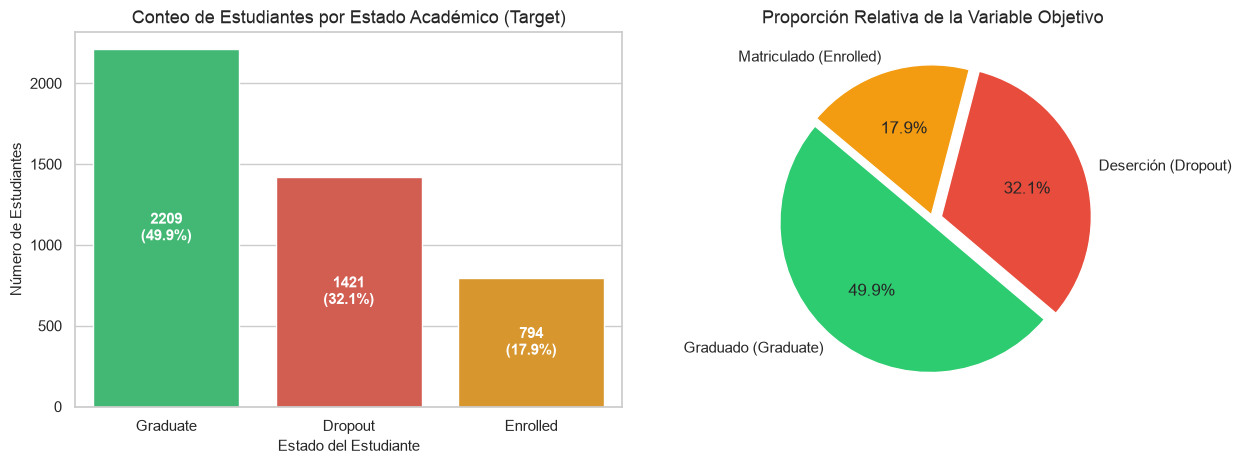

In [94]:
target_counts = df["Target"].value_counts()
target_pct = (df["Target"].value_counts(normalize=True) * 100).round(2)
resumen_target = pd.DataFrame({"Estudiantes": target_counts, "Porcentaje (%)": target_pct})
display(resumen_target)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
colores = {"Graduate": "#2ecc71", "Dropout": "#e74c3c", "Enrolled": "#f39c12"}

# Gráfico de barras
bars = sns.countplot(
    data=df, x="Target", order=["Graduate", "Dropout", "Enrolled"],
    palette=colores, ax=axes[0]
)
axes[0].set_title("Conteo de Estudiantes por Estado Académico (Target)")
axes[0].set_xlabel("Estado del Estudiante")
axes[0].set_ylabel("Número de Estudiantes")
for p in bars.patches:
    height = int(p.get_height())
    pct = height / len(df) * 100
    axes[0].annotate(f"{height}\n({pct:.1f}%)", (p.get_x() + p.get_width() / 2., height / 2),
                     ha="center", va="center", color="white", fontweight="bold", fontsize=11)

# Gráfico de proporción
axes[1].pie(
    target_counts[["Graduate", "Dropout", "Enrolled"]],
    labels=["Graduado (Graduate)", "Deserción (Dropout)", "Matriculado (Enrolled)"],
    autopct="%1.1f%%", startangle=140,
    colors=[colores["Graduate"], colores["Dropout"], colores["Enrolled"]],
    explode=(0.03, 0.06, 0.03), shadow=False
)
axes[1].set_title("Proporción Relativa de la Variable Objetivo")

plt.tight_layout()
plt.show()

### Distribución por Estado Académico

- **`Graduate` (Graduado):** **2,209 estudiantes (49.93%)** culminaron el plan de estudios.
- **`Dropout` (Deserción):** **1,421 estudiantes (32.12%)** abandonaron el programa académico.
- **`Enrolled` (Matriculado):** **794 estudiantes (17.95%)** continúan cursando sus estudios al cierre del corte de datos.

---
### 4.2 Distribución y Valores Atípicos en Variables Numéricas

Análisis descriptivo y detección de valores atípicos mediante rango intercuartílico ($IQR = Q_3 - Q_1$) sobre la edad de ingreso, la nota de admisión y los promedios de primer y segundo semestre.

,Variable,Media,Mediana,Q1 (25%),Q3 (75%),Límite Inf,Límite Sup,N° Outliers,% Outliers
0,Age at enrollment,23.27,20.00,19.00,25.00,10.00,34.00,441,9.97
1,Admission grade,126.98,126.10,117.90,134.80,92.55,160.15,86,1.94
2,Curricular units 1st sem (grade),10.64,12.29,11.00,13.40,7.40,17.00,726,16.41
3,Curricular units 2nd sem (grade),10.23,12.20,10.75,13.33,6.88,17.21,877,19.82


Age at enrollment        Admission grade         \
                      mean median            mean median   
Target                                                     
Dropout              26.07   23.0          124.96  123.6   
Enrolled             22.37   20.0          125.53  124.1   
Graduate             21.78   19.0          128.79  127.4   

         Curricular units 1st sem (grade)         \
                                     mean median   
Target                                             
Dropout                              7.26  10.93   
Enrolled                            11.13  12.00   
Graduate                            12.64  13.00   

         Curricular units 2nd sem (grade)         
                                     mean median  
Target                                            
Dropout                              5.90    0.0  
Enrolled                            11.12   12.0  
Graduate                            12.70   13.0

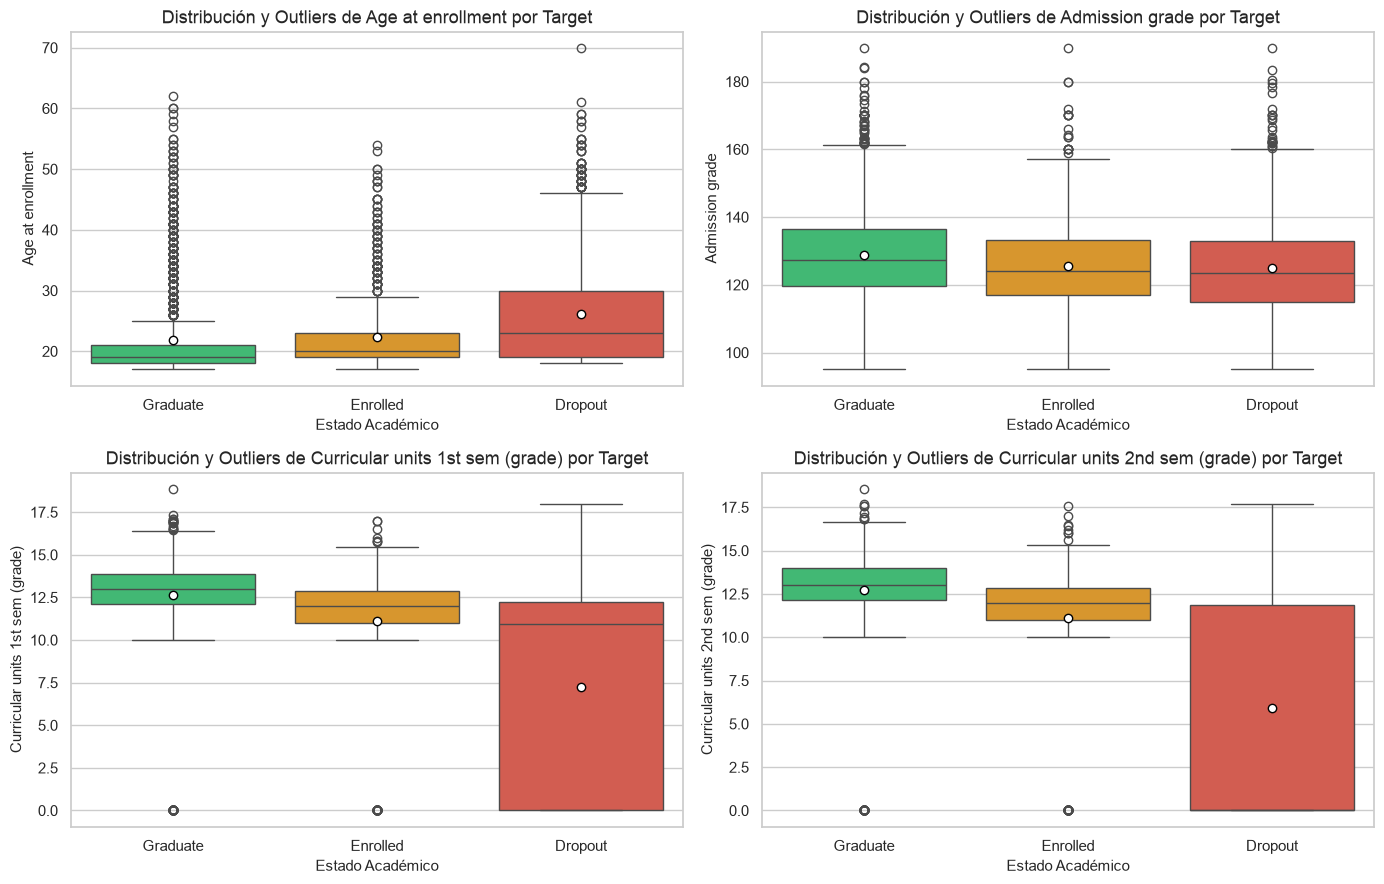

In [95]:
vars_continuas = [
    "Age at enrollment",
    "Admission grade",
    "Curricular units 1st sem (grade)",
    "Curricular units 2nd sem (grade)"
]

# Cuantificación de Outliers por regla 1.5 * IQR
reporte_outliers = []
for col in vars_continuas:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    n_out = ((df[col] < lim_inf) | (df[col] > lim_sup)).sum()
    reporte_outliers.append({
        "Variable": col,
        "Media": round(df[col].mean(), 2),
        "Mediana": round(df[col].median(), 2),
        "Q1 (25%)": round(q1, 2),
        "Q3 (75%)": round(q3, 2),
        "Límite Inf": round(lim_inf, 2),
        "Límite Sup": round(lim_sup, 2),
        "N° Outliers": int(n_out),
        "% Outliers": round(n_out / len(df) * 100, 2)
    })

display(pd.DataFrame(reporte_outliers))

# Resumen de medias y medianas agrupadas por Target
display(df.groupby("Target")[vars_continuas].agg(["mean", "median"]).round(2))

# Visualización con Boxplots por clase
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
orden = ["Graduate", "Enrolled", "Dropout"]
colores = {"Graduate": "#2ecc71", "Enrolled": "#f39c12", "Dropout": "#e74c3c"}

for ax, col in zip(axes.flatten(), vars_continuas):
    sns.boxplot(data=df, x="Target", y=col, order=orden, palette=colores, ax=ax, showmeans=True,
                meanprops={"marker": "o", "markerfacecolor": "white", "markeredgecolor": "black"})
    ax.set_title(f"Distribución y Outliers de {col} por Target")
    ax.set_xlabel("Estado Académico")

plt.tight_layout()
plt.show()

### Resultados

1. **Edad al matricularse.** La distribución presenta sesgo a la derecha: la mediana es de 20 años ($Q_1 = 19$, $Q_3 = 25$) y se registran 441 valores atípicos (9.97%) por encima de los 34 años, hasta un máximo de 70. Los desertores ingresan con una edad media de 26.07 años (mediana 23), frente a 21.78 años (mediana 19) en los graduados.
2. **Promedio semestral.** Los valores atípicos inferiores (726 en el primer semestre y 877 en el segundo) corresponden principalmente a promedios de 0.0. En los desertores, el promedio medio pasa de 7.26 en el primer semestre (mediana 10.93) a 5.90 en el segundo, con una mediana de 0.00. Los graduados mantienen una mediana de 13.00 en ambos semestres.
3. **Nota de admisión.** Se registran 86 valores atípicos (1.94%) en el extremo superior. Los graduados ingresan con una media de 128.79 frente a 124.96 de los desertores, una diferencia menor que la observada en el desempeño del primer año.

---
### 4.3 Factores Financieros, Socioeconómicos y Demográficos

Proporción de graduación, permanencia y deserción según el estado de pago de matrícula, condición de deudor, beca, género, jornada y desplazamiento geográfico.

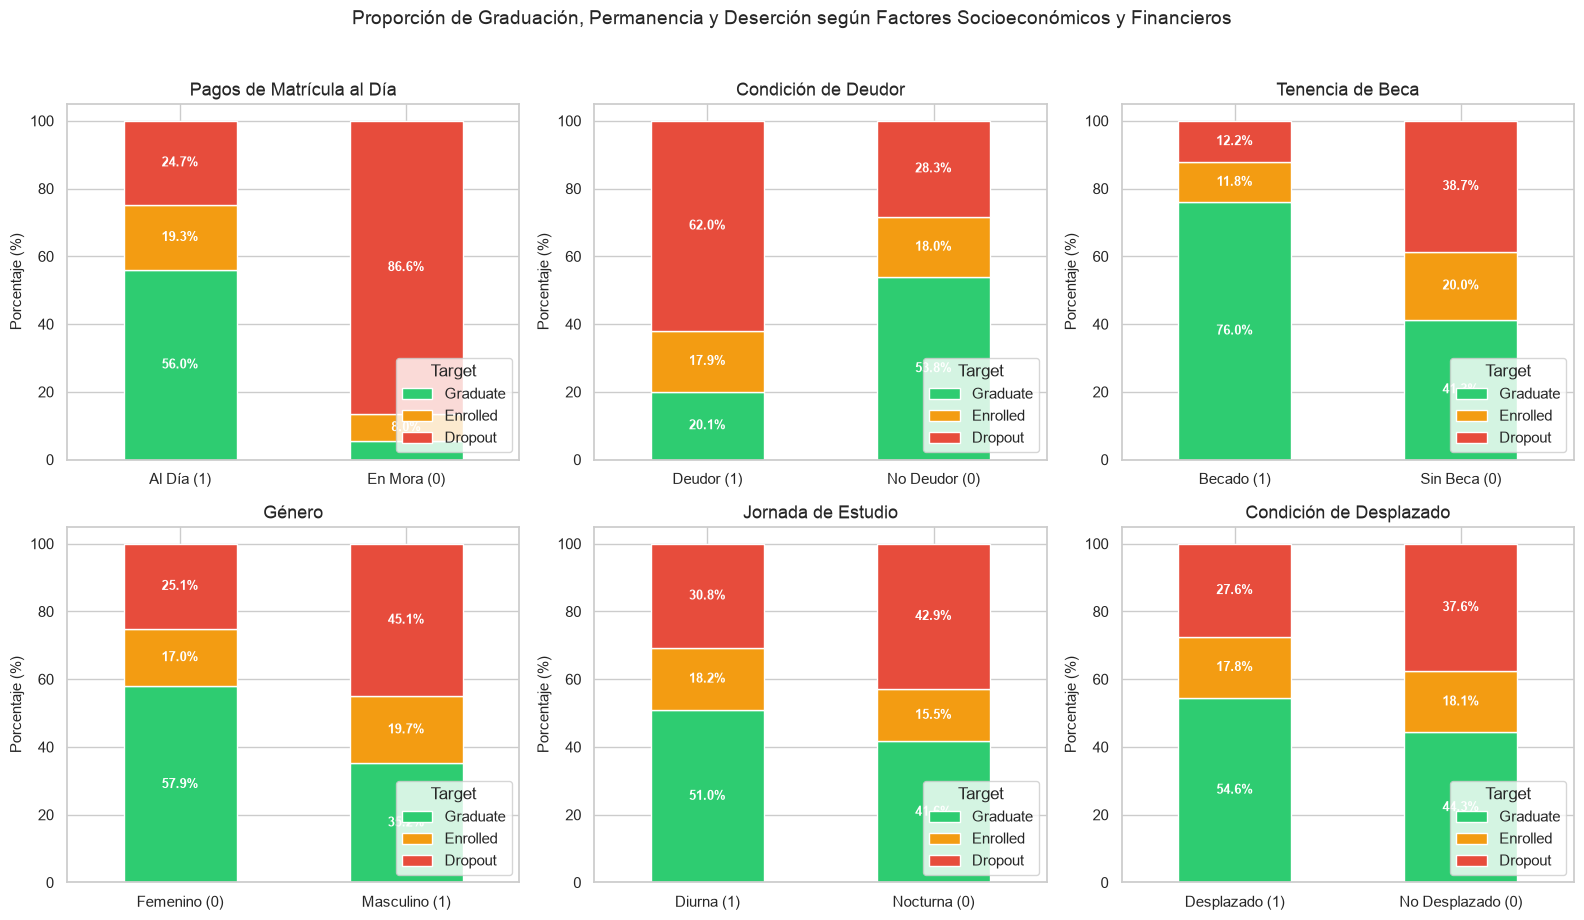

In [96]:
factores_binarios = [
    ("Tuition fees up to date", {0: "En Mora (0)", 1: "Al Día (1)"}, "Pagos de Matrícula al Día"),
    ("Debtor", {0: "No Deudor (0)", 1: "Deudor (1)"}, "Condición de Deudor"),
    ("Scholarship holder", {0: "Sin Beca (0)", 1: "Becado (1)"}, "Tenencia de Beca"),
    ("Gender", {0: "Femenino (0)", 1: "Masculino (1)"}, "Género"),
    ("Daytime/evening attendance", {0: "Nocturna (0)", 1: "Diurna (1)"}, "Jornada de Estudio"),
    ("Displaced", {0: "No Desplazado (0)", 1: "Desplazado (1)"}, "Condición de Desplazado")
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
colores = {"Graduate": "#2ecc71", "Enrolled": "#f39c12", "Dropout": "#e74c3c"}

for ax, (col, mapa, titulo) in zip(axes.flatten(), factores_binarios):
    serie_etiquetada = df[col].map(mapa)
    ct = pd.crosstab(serie_etiquetada, df["Target"], normalize="index")[["Graduate", "Enrolled", "Dropout"]] * 100
    ct.plot(kind="bar", stacked=True, color=[colores["Graduate"], colores["Enrolled"], colores["Dropout"]], ax=ax, rot=0)
    ax.set_title(titulo)
    ax.set_xlabel("")
    ax.set_ylabel("Porcentaje (%)")
    ax.legend(title="Target", loc="lower right", frameon=True)
    for c in ax.containers:
        labels = [f"{v.get_height():.1f}%" if v.get_height() > 6 else "" for v in c]
        ax.bar_label(c, labels=labels, label_type="center", color="white", fontweight="bold", fontsize=9)

plt.suptitle("Proporción de Graduación, Permanencia y Deserción según Factores Socioeconómicos y Financieros", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Resultados

1. **Matrícula al día.** De los 528 estudiantes con matrícula en mora, el 86.6% (457) desertó y el 5.5% (29) se graduó. Entre los 3,896 estudiantes con pagos al día, la deserción es de 24.7% y la graduación de 56.0%. Este resultado orienta la inclusión de normativa sobre alivios financieros y acuerdos de pago en el corpus documental.
2. **Condición de deudor.** De los 503 estudiantes con deudas activas, el 62.0% desertó y el 20.1% se graduó. En los no deudores, la deserción es de 28.3%.
3. **Beca.** De los 1,099 estudiantes becados, el 76.0% (835) se graduó y el 12.2% desertó. Entre los 3,325 sin beca, la deserción es de 38.7%.
4. **Género y jornada.** La deserción es de 45.1% en hombres ($n = 1,556$) y de 25.1% en mujeres ($n = 2,868$), con una graduación femenina de 57.9%. En la jornada nocturna ($n = 483$) la deserción es de 42.9%, frente a 30.8% en la diurna, es decir, 12.1 puntos porcentuales más.

---
### 4.4 Desempeño por Programa Académico (`Course`)

Distribución porcentual de deserción, permanencia y graduación en los 17 programas ofertados por la institución.

Target,Dropout,Enrolled,Graduate,Total_Estudiantes
Nombre_Curso,,,,
33 - Tec. Prod. Biocombustibles,66.7,25.0,8.3,12
9130 - Equinocultura,55.3,14.9,29.8,141
9119 - Ingeniería Informática,54.1,37.6,8.2,170
9991 - Administración (Nocturno),50.7,20.1,29.1,268
9853 - Educación Básica,44.3,26.0,29.7,192
9003 - Agronomía,41.0,17.6,41.4,210
9556 - Higiene Oral,38.4,19.8,41.9,86
171 - Diseño Animación y Multimedia,38.1,17.2,44.7,215
9254 - Turismo,38.1,16.3,45.6,252


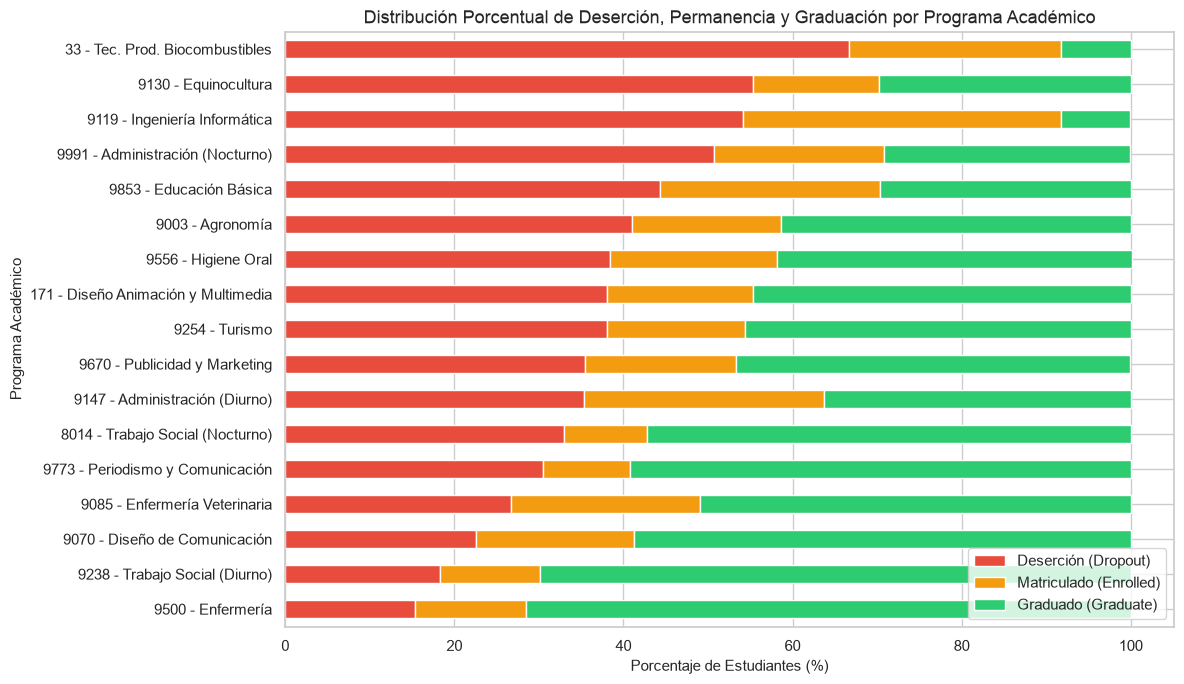

In [97]:
mapa_cursos = {
    33: "33 - Tec. Prod. Biocombustibles",
    171: "171 - Diseño Animación y Multimedia",
    8014: "8014 - Trabajo Social (Nocturno)",
    9003: "9003 - Agronomía",
    9070: "9070 - Diseño de Comunicación",
    9085: "9085 - Enfermería Veterinaria",
    9119: "9119 - Ingeniería Informática",
    9130: "9130 - Equinocultura",
    9147: "9147 - Administración (Diurno)",
    9238: "9238 - Trabajo Social (Diurno)",
    9254: "9254 - Turismo",
    9500: "9500 - Enfermería",
    9556: "9556 - Higiene Oral",
    9670: "9670 - Publicidad y Marketing",
    9773: "9773 - Periodismo y Comunicación",
    9853: "9853 - Educación Básica",
    9991: "9991 - Administración (Nocturno)"
}

df_cursos = df.copy()
df_cursos["Nombre_Curso"] = df_cursos["Course"].map(mapa_cursos)

tabla_cursos = pd.crosstab(df_cursos["Nombre_Curso"], df_cursos["Target"], normalize="index")[["Dropout", "Enrolled", "Graduate"]] * 100
tabla_cursos["Total_Estudiantes"] = df_cursos["Nombre_Curso"].value_counts()
tabla_cursos = tabla_cursos.sort_values(by="Dropout", ascending=False).round(1)
display(tabla_cursos)

fig, ax = plt.subplots(figsize=(12, 7))
tabla_cursos[["Dropout", "Enrolled", "Graduate"]].sort_values(by="Dropout", ascending=True).plot(
    kind="barh", stacked=True, color=["#e74c3c", "#f39c12", "#2ecc71"], ax=ax
)
ax.set_title("Distribución Porcentual de Deserción, Permanencia y Graduación por Programa Académico")
ax.set_xlabel("Porcentaje de Estudiantes (%)")
ax.set_ylabel("Programa Académico")
ax.legend(["Deserción (Dropout)", "Matriculado (Enrolled)", "Graduado (Graduate)"], loc="lower right")
plt.tight_layout()
plt.show()

### Resultados

1. **Programas con deserción superior al 50%.**
   - Tecnologías de Producción de Biocombustibles (`33`): 66.7% ($n = 12$).
   - Equinocultura (`9130`): 55.3% ($n = 141$).
   - Ingeniería Informática (`9119`): 54.1% ($n = 170$), con 37.6% de estudiantes aún matriculados y 8.2% de graduación.
   - Administración en jornada nocturna (`9991`): 50.7% ($n = 268$), frente a 35.3% en jornada diurna (`9147`, $n = 380$).
2. **Programas con mayor retención.**
   - Enfermería (`9500`) es el programa más numeroso ($n = 766$, 17.3% del total), con 71.5% de graduación y 15.4% de deserción.
   - Trabajo Social en jornada diurna (`9238`, $n = 355$) registra 69.9% de graduación y 18.3% de deserción.

---
### 4.5 Correlación de Variables Académicas y Macroeconómicas

Matriz de correlación de Pearson utilizando la codificación ordinal del estado académico (`Dropout = 0`, `Enrolled = 1`, `Graduate = 2`).

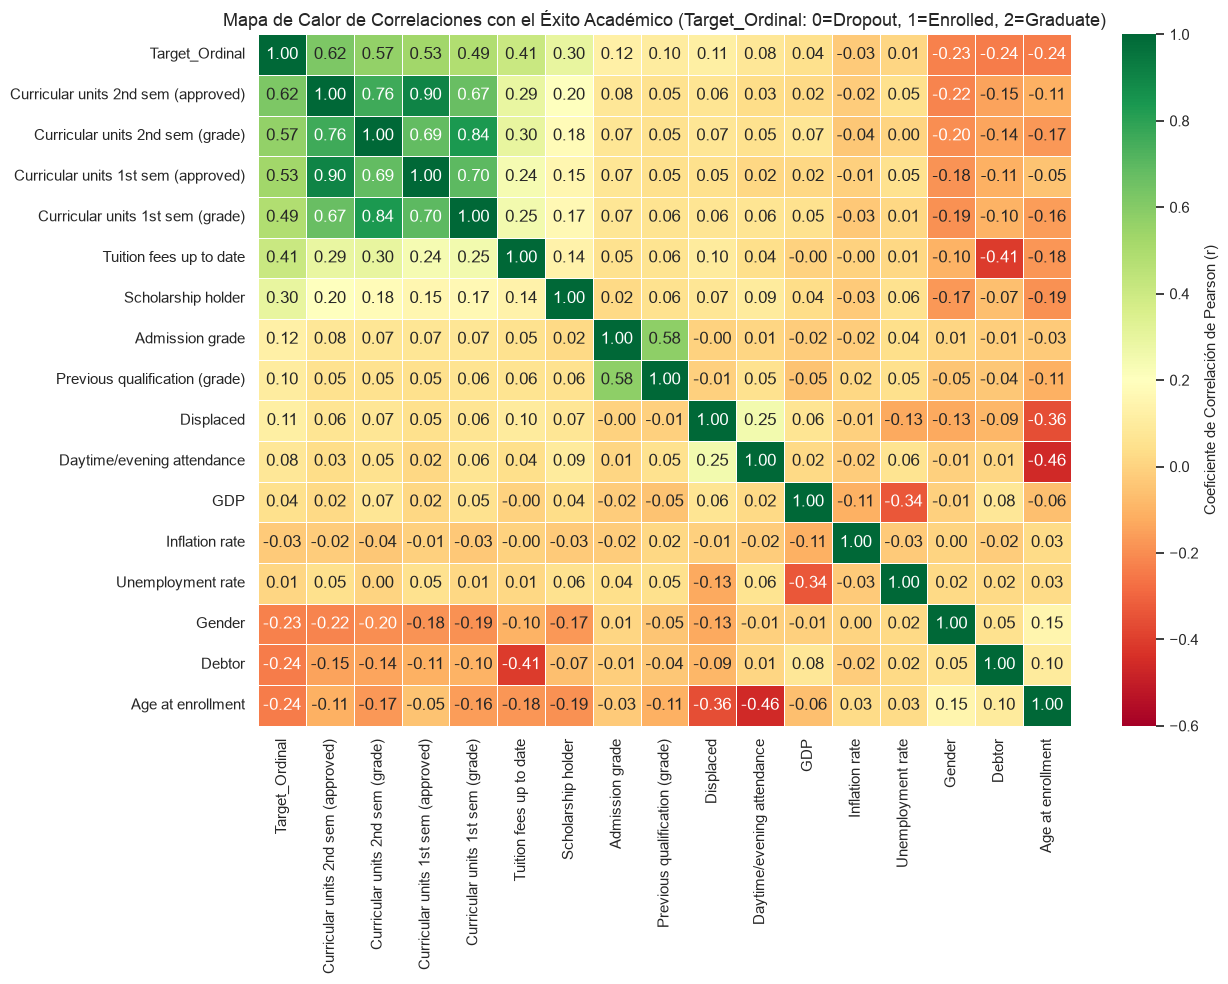

Correlación directa con el Éxito Académico (Target_Ordinal):


,Target_Ordinal
Target_Ordinal,1.000
Curricular units 2nd sem (approved),0.624
Curricular units 2nd sem (grade),0.567
Curricular units 1st sem (approved),0.529
Curricular units 1st sem (grade),0.485
Tuition fees up to date,0.410
Scholarship holder,0.298
Admission grade,0.121
Displaced,0.114
Previous qualification (grade),0.104


In [98]:
df_corr = df.copy()
df_corr["Target_Ordinal"] = df_corr["Target"].map({"Dropout": 0, "Enrolled": 1, "Graduate": 2})

cols_corr = [
    "Target_Ordinal",
    "Curricular units 2nd sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Curricular units 1st sem (approved)",
    "Curricular units 1st sem (grade)",
    "Tuition fees up to date",
    "Scholarship holder",
    "Admission grade",
    "Previous qualification (grade)",
    "Displaced",
    "Daytime/evening attendance",
    "GDP",
    "Inflation rate",
    "Unemployment rate",
    "Gender",
    "Debtor",
    "Age at enrollment"
]

matriz_corr = df_corr[cols_corr].corr()

plt.figure(figsize=(13, 10))
sns.heatmap(
    matriz_corr, annot=True, fmt=".2f", cmap="RdYlGn", vmin=-0.6, vmax=1.0,
    linewidths=0.5, cbar_kws={"label": "Coeficiente de Correlación de Pearson (r)"}
)
plt.title("Mapa de Calor de Correlaciones con el Éxito Académico (Target_Ordinal: 0=Dropout, 1=Enrolled, 2=Graduate)")
plt.tight_layout()
plt.show()

print("Correlación directa con el Éxito Académico (Target_Ordinal):")
display(matriz_corr[["Target_Ordinal"]].sort_values(by="Target_Ordinal", ascending=False).round(3))

### Resultados

1. **Correlaciones positivas.** Las variables con mayor correlación son las unidades aprobadas en el segundo semestre ($r = +0.624$), el promedio del segundo semestre ($r = +0.567$), las unidades aprobadas en el primer semestre ($r = +0.529$) y el promedio del primer semestre ($r = +0.485$). Las unidades aprobadas en ambos semestres están fuertemente relacionadas entre sí ($r = +0.90$). Entre las variables no académicas destacan la matrícula al día ($r = +0.410$) y la beca ($r = +0.298$).
2. **Correlaciones negativas.** La edad al ingreso ($r = -0.243$), la condición de deudor ($r = -0.241$) y el género masculino ($r = -0.229$).
3. **Variables macroeconómicas.** El desempleo ($r = +0.009$), la inflación ($r = -0.027$) y el PIB ($r = +0.044$) muestran correlaciones cercanas a cero. La permanencia se asocia principalmente con la situación individual del estudiante y su desempeño en el primer año.

---
## 5. Decodificación y Homologación Semántica de Variables

### 5.1 Variables codificadas

Diecisiete de las 36 columnas están codificadas con enteros definidos por el sistema administrativo de origen. La [documentación oficial del dataset](https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success) establece el siguiente significado para los códigos principales:

| Columna Original | Tipo Real | Ejemplos de Códigos Oficiales en UCI |
| :--- | :--- | :--- |
| `Marital Status` | Categórica Nominal | `1`: Soltero(a), `2`: Casado(a), `3`: Viudo(a), `4`: Divorciado(a), `5`: Unión libre, `6`: Separado(a) legalmente |
| `Application mode` | Categórica Nominal | `1`: 1ª fase contingente general, `15`: Estudiante internacional, `17`: 2ª fase general, `39`: Mayores de 23 años, `42`: Transferencia, `43`: Cambio de curso, `44`: Diploma especialización tecnológica |
| `Course` | Categórica Nominal | `33`: Tec. Biocombustibles, `171`: Diseño Animación/Multimedia, `8014`: Trabajo Social (Nocturno), `9003`: Agronomía, `9070`: Diseño Comunicación, `9085`: Enfermería Veterinaria, `9119`: Ingeniería Informática, `9130`: Equinocultura, `9147`: Administración, `9238`: Trabajo Social, `9254`: Turismo, `9500`: Enfermería, `9556`: Higiene Oral, `9670`: Publicidad y Marketing, `9773`: Periodismo, `9853`: Educación Básica, `9991`: Administración (Nocturno) |
| `Daytime/evening attendance` | Binaria | `1`: Diurna (*Daytime*), `0`: Nocturna (*Evening*) |
| `Previous qualification` | Categórica Ordinal/Nominal | `1`: Educación secundaria (12º año), `2`/`3`/`40`: Educación superior (Grado/Pregrado), `4`/`43`: Maestría, `5`: Doctorado, `19`: Básica 3er ciclo (9º-11º), `39`: Especialización tecnológica, `42`: Técnico superior profesional |
| `Nacionality` | Categórica Nominal | `1`: Portuguesa (97.5%), `41`: Brasileña, `26`: Santotomense, `6`: Española, `22`: Caboverdiana, `109`: Colombiana, etc. |
| `Mother's / Father's qualification` | Categórica | `1`: Secundaria (12º año), `2`/`3`/`40`: Ed. Superior, `19`: Básica 3er ciclo, `34`: **Desconocido**, `35`: No sabe leer ni escribir, `37`: Básica 1er ciclo (4º año), `38`: Básica 2do ciclo (6º-8º año) |
| `Mother's / Father's occupation` | Categórica ISCO | `0`: Estudiante, `1`: Directivos/Ejecutivos, `2`: Especialistas científicos/intelectuales, `3`: Técnicos nivel intermedio, `4`: Personal administrativo, `5`: Servicios personales/seguridad/vendedores, `6`: Agricultores calificados, `7`: Trabajadores calificados industria/construcción, `8`: Operadores de maquinaria, `9`: Trabajadores no calificados, `10`: Fuerzas Armadas, `90`: Otra situación, `99`: **En blanco/Desconocido**, más subcódigos específicos de 3 dígitos (`122`: Salud, `123`: Docentes, `125`: TIC, `191`: Limpieza, etc.) |
| `Displaced`, `Debtor`, `Tuition fees up to date`, `Scholarship holder`, `International`, `Educational special needs` | Binarias | `1`: Sí (*Yes*), `0`: No (*No*) |
| `Gender` | Binaria | `1`: Masculino (*Male*), `0`: Femenino (*Female*) |
| `Target` | Categórica (3 clases) | `Dropout`: Deserción, `Enrolled`: Matriculado, `Graduate`: Graduado |

---

### 5.2 Estrategia de homologación

Los códigos numéricos se traducen a etiquetas en español por tres razones:

1. **Semántica.** Un modelo de embeddings no interpreta un código como `9119`; la etiqueta «Ingeniería Informática» sí aporta significado al vector.
2. **Idioma.** El corpus normativo y las consultas están en español, lo que favorece la similitud coseno entre ellos.
3. **Filtrado.** Campos como `programa_academico` o `matricula_al_dia` se almacenan como metadatos (*payload*) y permiten búsquedas vectoriales filtradas.

Se generan tres archivos en `data/csv/`:

| Archivo | Contenido |
| :--- | :--- |
| `UCI Predict Students Dropout.csv` | Dataset original con códigos numéricos. |
| `UCI_Students_Dropout_Homologado_ES.csv` | 41 columnas en español con los códigos traducidos y tres indicadores derivados: tasa de aprobación del primer semestre, tasa de aprobación del segundo semestre y nivel de riesgo (`Alto`, `Medio`, `Bajo`). |
| `UCI_Students_RAG_Perfiles.csv` | Perfil narrativo por estudiante (`texto_semantico_rag`) con sus metadatos, para su vectorización. |

In [99]:
# ==============================================================================
# 5.2 DICCIONARIOS DE DECODIFICACIÓN OFICIAL (CATÁLOGO UCI #697 AL ESPAÑOL)
# ==============================================================================

MARITAL_STATUS_MAP = {
    1: "Soltero(a)", 2: "Casado(a)", 3: "Viudo(a)",
    4: "Divorciado(a)", 5: "Unión libre (Facto union)", 6: "Separado(a) legalmente"
}

APPLICATION_MODE_MAP = {
    1: "1ª fase - contingente general",
    2: "Ordenanza N.º 612/93",
    5: "1ª fase - contingente especial (Isla Azores)",
    7: "Titulares de otros cursos superiores",
    10: "Ordenanza N.º 854-B/99",
    15: "Estudiante internacional (pregrado)",
    16: "1ª fase - contingente especial (Isla Madeira)",
    17: "2ª fase - contingente general",
    18: "3ª fase - contingente general",
    26: "Ordenanza N.º 533-A/99, ítem b2 (Plan diferente)",
    27: "Ordenanza N.º 533-A/99, ítem b3 (Otra institución)",
    39: "Mayores de 23 años",
    42: "Transferencia",
    43: "Cambio de curso/programa",
    44: "Titulares de diploma de especialización tecnológica",
    51: "Cambio de institución/curso",
    53: "Titulares de diploma de ciclo corto",
    57: "Cambio de institución/curso (Internacional)"
}

COURSE_MAP = {
    33: "Tecnologías de Producción de Biocombustibles",
    171: "Diseño de Animación y Multimedia",
    8014: "Trabajo Social (Jornada nocturna)",
    9003: "Agronomía",
    9070: "Diseño de Comunicación",
    9085: "Enfermería Veterinaria",
    9119: "Ingeniería Informática",
    9130: "Equinocultura",
    9147: "Administración (Management)",
    9238: "Trabajo Social",
    9254: "Turismo",
    9500: "Enfermería",
    9556: "Higiene Oral",
    9670: "Gestión de Publicidad y Marketing",
    9773: "Periodismo y Comunicación",
    9853: "Educación Básica",
    9991: "Administración (Jornada nocturna)"
}

ATTENDANCE_MAP = {1: "Diurna", 0: "Nocturna"}

PREV_QUALIFICATION_MAP = {
    1: "Educación secundaria (Bachillerato completo)",
    2: "Educación superior - pregrado (Bachelor)",
    3: "Educación superior - título profesional (Degree)",
    4: "Educación superior - maestría",
    5: "Educación superior - doctorado",
    6: "Frecuencia de educación superior (incompleto)",
    9: "Grado 12 de escolaridad - no completado",
    10: "Grado 11 de escolaridad - no completado",
    12: "Otro - Grado 11 de escolaridad",
    14: "Grado 10 de escolaridad",
    15: "Grado 10 de escolaridad - no completado",
    19: "Educación básica 3er ciclo (9º/10º/11º año) o equiv.",
    38: "Educación básica 2do ciclo (6º/7º/8º año) o equiv.",
    39: "Curso de especialización tecnológica",
    40: "Educación superior - grado (1er ciclo)",
    42: "Curso técnico superior profesional",
    43: "Educación superior - maestría (2do ciclo)"
}

NATIONALITY_MAP = {
    1: "Portuguesa", 2: "Alemana", 6: "Española", 11: "Italiana",
    13: "Neerlandesa", 14: "Inglesa", 17: "Lituana", 21: "Angoleña",
    22: "Caboverdiana", 24: "Guineana", 25: "Mozambiqueña", 26: "Santotomense",
    32: "Turca", 41: "Brasileña", 62: "Rumana", 100: "Moldava",
    101: "Mexicana", 103: "Ucraniana", 105: "Rusa", 108: "Cubana", 109: "Colombiana"
}

PARENT_QUALIFICATION_MAP = {
    1: "Educación secundaria (12º año o equiv.)",
    2: "Educación superior - pregrado (Bachelor)",
    3: "Educación superior - título profesional (Degree)",
    4: "Educación superior - maestría",
    5: "Educación superior - doctorado",
    6: "Frecuencia de educación superior",
    9: "12º año de escolaridad - no completado",
    10: "11º año de escolaridad - no completado",
    11: "7º año (antiguo)",
    12: "Otro - 11º año de escolaridad",
    13: "2º año curso complementario de secundaria",
    14: "10º año de escolaridad",
    18: "Curso general de comercio",
    19: "Educación básica 3er ciclo (9º/10º/11º año) o equiv.",
    20: "Curso complementario de secundaria",
    22: "Curso técnico-profesional",
    25: "Curso complementario de secundaria - no concluido",
    26: "7º año de escolaridad",
    27: "2do ciclo del curso general de secundaria",
    29: "9º año de escolaridad - no completado",
    30: "8º año de escolaridad",
    31: "Curso general de administración y comercio",
    33: "Contabilidad y administración suplementaria",
    34: "Desconocido",
    35: "No sabe leer ni escribir",
    36: "Sabe leer sin tener 4º año de escolaridad",
    37: "Educación básica 1er ciclo (4º/5º año) o equiv.",
    38: "Educación básica 2do ciclo (6º/7º/8º año) o equiv.",
    39: "Curso de especialización tecnológica",
    40: "Educación superior - grado (1er ciclo)",
    41: "Curso de estudios superiores especializados",
    42: "Curso técnico superior profesional",
    43: "Educación superior - maestría (2do ciclo)",
    44: "Educación superior - doctorado (3er ciclo)"
}

PARENT_OCCUPATION_MAP = {
    0: "Estudiante",
    1: "Representantes del poder legislativo/ejecutivo, directores y gerentes",
    2: "Especialistas en actividades intelectuales y científicas",
    3: "Técnicos y profesiones de nivel intermedio",
    4: "Personal administrativo",
    5: "Trabajadores de servicios personales, protección, seguridad y vendedores",
    6: "Agricultores y trabajadores calificados agropecuarios/pesqueros",
    7: "Trabajadores calificados de la industria, construcción y artesanos",
    8: "Operadores de instalaciones, maquinaria y ensambladores",
    9: "Trabajadores no calificados",
    10: "Profesiones de las Fuerzas Armadas",
    90: "Otra situación",
    99: "Desconocido / En blanco",
    101: "Oficiales de las Fuerzas Armadas",
    102: "Sargentos de las Fuerzas Armadas",
    103: "Otro personal de las Fuerzas Armadas",
    112: "Directores de servicios administrativos y comerciales",
    114: "Directores de hotelería, restauración, comercio y otros servicios",
    121: "Especialistas en ciencias físicas, matemáticas, ingeniería y afines",
    122: "Profesionales de la salud",
    123: "Docentes / Profesores",
    124: "Especialistas en finanzas, contabilidad y organización administrativa",
    125: "Especialistas en tecnologías de la información y comunicación (TIC)",
    131: "Técnicos y profesionales de ciencias e ingeniería de nivel intermedio",
    132: "Técnicos y profesionales de nivel intermedio de la salud",
    134: "Técnicos de nivel intermedio de servicios jurídicos, sociales, deportivos y culturales",
    135: "Técnicos en tecnologías de la información y comunicación",
    141: "Empleados de oficina, secretarios en general y operadores de procesamiento de datos",
    143: "Operadores de datos, contabilidad, estadística y servicios financieros",
    144: "Otro personal de apoyo administrativo",
    151: "Trabajadores de servicios personales",
    152: "Vendedores",
    153: "Trabajadores de cuidado personal y similares",
    154: "Personal de servicios de protección y seguridad",
    161: "Agricultores orientados al mercado y trabajadores agropecuarios calificados",
    163: "Agricultores, ganaderos y pescadores de subsistencia",
    171: "Trabajadores calificados de la construcción y similares (excepto electricistas)",
    172: "Trabajadores calificados en metalurgia, trabajo de metales y similares",
    173: "Trabajadores calificados en impresión, fabricación de instrumentos de precisión, joyeros y artesanos",
    174: "Trabajadores calificados en electricidad y electrónica",
    175: "Trabajadores en procesamiento de alimentos, madera, vestuario y otras industrias",
    181: "Operadores de instalaciones fijas y máquinas",
    182: "Trabajadores de ensamblaje",
    183: "Conductores de vehículos y operadores de equipos móviles",
    191: "Trabajadores de limpieza",
    192: "Trabajadores no calificados en agricultura, ganadería, pesca y silvicultura",
    193: "Trabajadores no calificados en industria extractiva, construcción, manufactura y transporte",
    194: "Asistentes de preparación de comidas",
    195: "Vendedores ambulantes (excepto alimentos) y prestadores de servicios callejeros"
}

BINARY_SI_NO = {1: "Sí", 0: "No"}
GENDER_MAP = {1: "Masculino", 0: "Femenino"}
TARGET_MAP = {"Dropout": "Deserción", "Enrolled": "Matriculado", "Graduate": "Graduado"}

print("Diccionarios de decodificación cargados correctamente.")

Diccionarios de decodificación cargados correctamente.


### 5.3 Construcción del dataset tabular homologado, indicadores de riesgo y persistencia SQL

Aplicación de los diccionarios de decodificación sobre los 4,424 registros, cálculo de tasas de aprobación en primer y segundo semestre, clasificación del nivel de riesgo temprano (`Bajo`, `Medio`, `Alto`) y almacenamiento estructurado tanto en formato CSV (`UCI_Students_Dropout_Homologado_ES.csv`) como en una base de datos relacional SQL (`sqlite3` en `data/sql/cun_permanencia_academica.db`).

In [100]:
df_homologado = pd.DataFrame()
df_homologado["id_estudiante"] = [f"EST-{i:04d}" for i in range(1, len(df) + 1)]
df_homologado["estado_civil"] = df["Marital Status"].map(MARITAL_STATUS_MAP)
df_homologado["modo_admision"] = df["Application mode"].map(APPLICATION_MODE_MAP)
df_homologado["orden_preferencia_aplicacion"] = df["Application order"]
df_homologado["programa_academico"] = df["Course"].map(COURSE_MAP)
df_homologado["jornada"] = df["Daytime/evening attendance"].map(ATTENDANCE_MAP)
df_homologado["nivel_educativo_previo"] = df["Previous qualification"].map(PREV_QUALIFICATION_MAP)
df_homologado["nota_educacion_previa"] = df["Previous qualification (grade)"]
df_homologado["nacionalidad"] = df["Nacionality"].map(NATIONALITY_MAP)
df_homologado["escolaridad_madre"] = df["Mother's qualification"].map(PARENT_QUALIFICATION_MAP)
df_homologado["escolaridad_padre"] = df["Father's qualification"].map(PARENT_QUALIFICATION_MAP)
df_homologado["ocupacion_madre"] = df["Mother's occupation"].map(PARENT_OCCUPATION_MAP)
df_homologado["ocupacion_padre"] = df["Father's occupation"].map(PARENT_OCCUPATION_MAP)
df_homologado["nota_admision"] = df["Admission grade"]
df_homologado["desplazado"] = df["Displaced"].map(BINARY_SI_NO)
df_homologado["necesidades_educativas_especiales"] = df["Educational special needs"].map(BINARY_SI_NO)
df_homologado["deudor"] = df["Debtor"].map(BINARY_SI_NO)
df_homologado["matricula_al_dia"] = df["Tuition fees up to date"].map(BINARY_SI_NO)
df_homologado["genero"] = df["Gender"].map(GENDER_MAP)
df_homologado["becado"] = df["Scholarship holder"].map(BINARY_SI_NO)
df_homologado["edad_inscripcion"] = df["Age at enrollment"]
df_homologado["internacional"] = df["International"].map(BINARY_SI_NO)

# Variables académicas 1er y 2do semestre + Tasas de aprobación derivadas
df_homologado["unidades_1er_sem_homologadas"] = df["Curricular units 1st sem (credited)"]
df_homologado["unidades_1er_sem_inscritas"] = df["Curricular units 1st sem (enrolled)"]
df_homologado["unidades_1er_sem_evaluadas"] = df["Curricular units 1st sem (evaluations)"]
df_homologado["unidades_1er_sem_aprobadas"] = df["Curricular units 1st sem (approved)"]
df_homologado["promedio_1er_sem"] = df["Curricular units 1st sem (grade)"].round(2)
df_homologado["unidades_1er_sem_sin_evaluar"] = df["Curricular units 1st sem (without evaluations)"]
df_homologado["tasa_aprobacion_1er_sem_pct"] = np.where(
    df_homologado["unidades_1er_sem_inscritas"] > 0,
    (df_homologado["unidades_1er_sem_aprobadas"] / df_homologado["unidades_1er_sem_inscritas"] * 100).round(1),
    0.0
)

df_homologado["unidades_2do_sem_homologadas"] = df["Curricular units 2nd sem (credited)"]
df_homologado["unidades_2do_sem_inscritas"] = df["Curricular units 2nd sem (enrolled)"]
df_homologado["unidades_2do_sem_evaluadas"] = df["Curricular units 2nd sem (evaluations)"]
df_homologado["unidades_2do_sem_aprobadas"] = df["Curricular units 2nd sem (approved)"]
df_homologado["promedio_2do_sem"] = df["Curricular units 2nd sem (grade)"].round(2)
df_homologado["unidades_2do_sem_sin_evaluar"] = df["Curricular units 2nd sem (without evaluations)"]
df_homologado["tasa_aprobacion_2do_sem_pct"] = np.where(
    df_homologado["unidades_2do_sem_inscritas"] > 0,
    (df_homologado["unidades_2do_sem_aprobadas"] / df_homologado["unidades_2do_sem_inscritas"] * 100).round(1),
    0.0
)

df_homologado["tasa_desempleo"] = df["Unemployment rate"]
df_homologado["tasa_inflacion"] = df["Inflation rate"]
df_homologado["variacion_pib"] = df["GDP"]

# Clasificación de Nivel de Riesgo Temprano
niveles_riesgo = []
for _, row in df_homologado.iterrows():
    factores = []
    if row["matricula_al_dia"] == "No":
        factores.append("mora en pago de matrícula")
    if row["deudor"] == "Sí":
        factores.append("deuda activa con la institución")
    if row["unidades_1er_sem_inscritas"] > 0 and row["tasa_aprobacion_1er_sem_pct"] < 50:
        factores.append("baja aprobación en 1er semestre")
    if row["unidades_2do_sem_inscritas"] > 0 and row["tasa_aprobacion_2do_sem_pct"] < 50:
        factores.append("baja aprobación en 2do semestre")
    if row["unidades_1er_sem_inscritas"] == 0 and row["unidades_2do_sem_inscritas"] == 0:
        factores.append("sin inscripción de unidades curriculares")

    if len(factores) >= 2 or row["matricula_al_dia"] == "No":
        riesgo = "Alto"
    elif len(factores) == 1:
        riesgo = "Medio"
    else:
        riesgo = "Bajo"
    niveles_riesgo.append(riesgo)

df_homologado["nivel_riesgo_alerta"] = niveles_riesgo
df_homologado["estado_estudiante"] = df["Target"].map(TARGET_MAP)

HOMOLOGADO_PATH = DATA_DIR / "UCI_Students_Dropout_Homologado_ES.csv"
df_homologado.to_csv(HOMOLOGADO_PATH, sep=";", index=False)

print(f"Dataset homologado guardado en: {HOMOLOGADO_PATH} -> Forma: {df_homologado.shape}")
print(f"Verificación de valores nulos tras homologación: {df_homologado.isnull().sum().sum()}")
display(df_homologado.head(3))

# Persistencia relacional en Base de Datos SQL (SQLite) y consulta de validación
import sqlite3
SQL_DIR = Path("data/sql")
SQL_DIR.mkdir(parents=True, exist_ok=True)
SQL_DB_PATH = SQL_DIR / "cun_permanencia_academica.db"

with sqlite3.connect(SQL_DB_PATH) as conn_sql:
    df_homologado.to_sql("estudiantes_homologados", conn_sql, if_exists="replace", index=False)
    consulta_sql_riesgo = pd.read_sql_query("""
        SELECT
            nivel_riesgo_alerta AS Nivel_Riesgo,
            COUNT(*) AS Total_Estudiantes,
            SUM(CASE WHEN estado_estudiante = 'Deserción' THEN 1 ELSE 0 END) AS Desertores,
            ROUND(AVG(tasa_aprobacion_1er_sem_pct), 1) AS Aprobacion_Media_1er_Sem_Pct
        FROM estudiantes_homologados
        GROUP BY nivel_riesgo_alerta
        ORDER BY Total_Estudiantes DESC
    """, conn_sql)

print(f"Base de datos SQL actualizada en: {SQL_DB_PATH} (tabla: 'estudiantes_homologados')")
display(consulta_sql_riesgo)

Dataset homologado guardado en: data/csv/UCI_Students_Dropout_Homologado_ES.csv -> Forma: (4424, 41)
Verificación de valores nulos tras homologación: 0


,id_estudiante,estado_civil,modo_admision,orden_preferencia_aplicacion,programa_academico,jornada,nivel_educativo_previo,nota_educacion_previa,nacionalidad,escolaridad_madre,escolaridad_padre,ocupacion_madre,ocupacion_padre,nota_admision,desplazado,necesidades_educativas_especiales,deudor,matricula_al_dia,genero,becado,edad_inscripcion,internacional,unidades_1er_sem_homologadas,unidades_1er_sem_inscritas,unidades_1er_sem_evaluadas,unidades_1er_sem_aprobadas,promedio_1er_sem,unidades_1er_sem_sin_evaluar,tasa_aprobacion_1er_sem_pct,unidades_2do_sem_homologadas,unidades_2do_sem_inscritas,unidades_2do_sem_evaluadas,unidades_2do_sem_aprobadas,promedio_2do_sem,unidades_2do_sem_sin_evaluar,tasa_aprobacion_2do_sem_pct,tasa_desempleo,tasa_inflacion,variacion_pib,nivel_riesgo_alerta,estado_estudiante
0,EST-0001,Soltero(a),2ª fase - contingente general,5,Diseño de Animación y Multimedia,Diurna,Educación secundaria (Bachillerato completo),122.0,Portuguesa,Educación básica 3er ciclo (9º/10º/11º año) o equiv.,Otro - 11º año de escolaridad,"Trabajadores de servicios personales, protección, seguridad y vendedores",Trabajadores no calificados,127.3,Sí,No,No,Sí,Masculino,No,20,No,0,0,0,0,0.0,0,0.0,0,0,0,0,0.00,0,0.0,10.8,1.4,1.74,Medio,Deserción
1,EST-0002,Soltero(a),Estudiante internacional (pregrado),1,Turismo,Diurna,Educación secundaria (Bachillerato completo),160.0,Portuguesa,Educación secundaria (12º año o equiv.),Educación superior - título profesional (Degree),Técnicos y profesiones de nivel intermedio,Técnicos y profesiones de nivel intermedio,142.5,Sí,No,No,No,Masculino,No,19,No,0,6,6,6,14.0,0,100.0,0,6,6,6,13.67,0,100.0,13.9,-0.3,0.79,Alto,Graduado
2,EST-0003,Soltero(a),1ª fase - contingente general,5,Diseño de Comunicación,Diurna,Educación secundaria (Bachillerato completo),122.0,Portuguesa,Educación básica 1er ciclo (4º/5º año) o equiv.,Educación básica 1er ciclo (4º/5º año) o equiv.,Trabajadores no calificados,Trabajadores no calificados,124.8,Sí,No,No,No,Masculino,No,19,No,0,6,0,0,0.0,0,0.0,0,6,0,0,0.00,0,0.0,10.8,1.4,1.74,Alto,Deserción


Base de datos SQL actualizada en: data/sql/cun_permanencia_academica.db (tabla: 'estudiantes_homologados')


,Nivel_Riesgo,Total_Estudiantes,Desertores,Aprobacion_Media_1er_Sem_Pct
0,Bajo,2783,285,90.3
1,Alto,1084,929,25.6
2,Medio,557,207,53.6


### 5.4 Generación de perfiles narrativos semánticos para RAG

Transformación de cada registro tabular homologado en una ficha narrativa en lenguaje natural (`texto_semantico_rag`) acompañada de metadatos estructurados para filtrado en la base vectorial.

In [101]:
textos_rag = []
for _, row in df_homologado.iterrows():
    texto = (
        f"Ficha de seguimiento académico {row['id_estudiante']}: Estudiante de género {row['genero'].lower()}, "
        f"{row['edad_inscripcion']} años al ingreso, estado civil {row['estado_civil'].lower()}, "
        f"matriculado en el programa de {row['programa_academico']} (jornada {row['jornada'].lower()}) "
        f"mediante modalidad '{row['modo_admision']}'. "
        f"Perfil socioeconómico y financiero: desplazado={row['desplazado']}, becado={row['becado']}, "
        f"deudor={row['deudor']}, matrícula al día={row['matricula_al_dia']}. "
        f"Desempeño 1er semestre: {row['unidades_1er_sem_aprobadas']} de {row['unidades_1er_sem_inscritas']} "
        f"unidades aprobadas ({row['tasa_aprobacion_1er_sem_pct']}%) con promedio {row['promedio_1er_sem']}/20. "
        f"Desempeño 2do semestre: {row['unidades_2do_sem_aprobadas']} de {row['unidades_2do_sem_inscritas']} "
        f"unidades aprobadas ({row['tasa_aprobacion_2do_sem_pct']}%) con promedio {row['promedio_2do_sem']}/20. "
        f"Nivel de alerta temprana: {row['nivel_riesgo_alerta']}. "
        f"Resultado académico final registrado: {row['estado_estudiante']}."
    )
    textos_rag.append(texto)

df_rag_perfiles = pd.DataFrame({
    "id_documento": df_homologado["id_estudiante"],
    "tipo_fuente": "registro_tabular_uci_697",
    "pilar": "Educación",
    "programa_academico": df_homologado["programa_academico"],
    "jornada": df_homologado["jornada"],
    "matricula_al_dia": df_homologado["matricula_al_dia"],
    "deudor": df_homologado["deudor"],
    "becado": df_homologado["becado"],
    "nivel_riesgo_alerta": df_homologado["nivel_riesgo_alerta"],
    "estado_estudiante": df_homologado["estado_estudiante"],
    "texto_semantico_rag": textos_rag
})

RAG_PATH = DATA_DIR / "UCI_Students_RAG_Perfiles.csv"
df_rag_perfiles.to_csv(RAG_PATH, sep=";", index=False)

print(f"Dataset de perfiles RAG guardado en: {RAG_PATH} -> Forma: {df_rag_perfiles.shape}")
print("\nEjemplo de Ficha Narrativa Semántica lista para Vectorización (Embeddings):")
print("-" * 95)
print(df_rag_perfiles.loc[0, "texto_semantico_rag"])
print("-" * 95)
print(df_rag_perfiles.loc[2, "texto_semantico_rag"])

Dataset de perfiles RAG guardado en: data/csv/UCI_Students_RAG_Perfiles.csv -> Forma: (4424, 11)

Ejemplo de Ficha Narrativa Semántica lista para Vectorización (Embeddings):
-----------------------------------------------------------------------------------------------
Ficha de seguimiento académico EST-0001: Estudiante de género masculino, 20 años al ingreso, estado civil soltero(a), matriculado en el programa de Diseño de Animación y Multimedia (jornada diurna) mediante modalidad '2ª fase - contingente general'. Perfil socioeconómico y financiero: desplazado=Sí, becado=No, deudor=No, matrícula al día=Sí. Desempeño 1er semestre: 0 de 0 unidades aprobadas (0.0%) con promedio 0.0/20. Desempeño 2do semestre: 0 de 0 unidades aprobadas (0.0%) con promedio 0.0/20. Nivel de alerta temprana: Medio. Resultado académico final registrado: Deserción.
-----------------------------------------------------------------------------------------------
Ficha de seguimiento académico EST-0003: Estudiante 

### Resultado de la Homologación

Se procesaron los **4,424 registros** sin valores faltantes (`0 NaN`), generando **41 columnas** en el archivo tabular homologado y **11 campos** en el archivo de perfiles semánticos para indexación vectorial.

---
## 6. Corpus Normativo CUN, Fragmentación e Indexación Vectorial

El corpus documental está conformado por tres documentos normativos oficiales de la **Corporación Unificada Nacional de Educación Superior (CUN)** almacenados en `data/docs/`:

| Archivo en `data/docs/` | Documento Oficial | Alcance Normativo |
| :--- | :--- | :--- |
| `reglamento-estudiantil.md` | **Acuerdo No. 019 de 2023** (Consejo Directivo) | Calidad y pérdida de calidad de estudiante, admisión, matrícula, homologaciones, evaluación, promedio ponderado, prueba académica y régimen disciplinario. |
| `reglamento-bienestar.md` | **Acuerdo No. 022 de 2018** (Consejo Directivo) | Modelo de Bienestar Institucional, principios de inclusión y permanencia, dimensiones de acompañamiento, estímulos y régimen general de becas. |
| `resolucion-007-2024-becas-rendimiento-academico.md` | **Resolución Rectoral No. 007 de 2024** | Presupuesto y asignación de becas por excelencia académica (promedios $\ge 4.5$ para 50% y $\ge 4.3$ para 25%) y becas de bienestar institucional. |

### 6.1 Funciones de lectura de metadatos, limpieza y segmentación por artículos

Cada archivo Markdown incluye un encabezado `YAML frontmatter` (`documento`, `institucion`, `tipo_fuente`, `tema`, `fecha`). El pipeline de fragmentación limpia notas editoriales (`limpiar_cuerpo`), identifica la jerarquía de capítulos y artículos mediante expresiones regulares (`dividir_por_articulos`) y aplica `RecursiveCharacterTextSplitter` sobre cada artículo, anteponiendo el contexto `Capítulo | Artículo` a cada fragmento.

In [102]:
DOCS_DIR = Path("data/docs")

ORDINALES = r"(?:Primero|Segundo|Tercero|Cuarto|Quinto|Sexto|S[ée]ptimo|Octavo|Noveno|D[ée]cimo)"
RE_ART = re.compile(
    rf"^(?:#{{1,6}}\s*)?(?:\*\*)?\s*(?:ART[ÍI]CULO|Art)\.?\s*(\d+|{ORDINALES})\s*[ºo°]?\s*[\.:\-–]",
    re.I,
)
RE_CAP = re.compile(r"^##\s+(?:LIBRO|CAP[ÍI]TULO)\b", re.I)


def extraer_frontmatter_y_cuerpo(texto):
    """Extrae los metadatos del encabezado YAML y devuelve (metadatos, cuerpo)."""
    metadatos, cuerpo = {}, texto
    if texto.startswith("---\n"):
        partes = texto.split("---\n", 2)
        if len(partes) == 3:
            for linea in partes[1].strip().splitlines():
                if ":" in linea:
                    k, v = linea.split(":", 1)
                    metadatos[k.strip()] = v.strip()
            cuerpo = partes[2].strip()
    return metadatos, cuerpo


def limpiar_cuerpo(cuerpo):
    """Elimina notas de edición (líneas '>') y encabezados Markdown espurios dentro del articulado."""
    lineas = [l for l in cuerpo.splitlines() if not l.lstrip().startswith(">")]
    return "\n".join(
        l if RE_ART.match(l) else re.sub(r"^#{3,6}\s+", "", l) for l in lineas
    ).strip()


def dividir_por_articulos(cuerpo):
    """Divide el texto por artículo y conserva el capítulo vigente."""
    secciones, capitulo, etiqueta, buffer = [], "", "Preámbulo", []
    lineas, i = cuerpo.splitlines(), 0

    def cerrar():
        txt = "\n".join(buffer).strip()
        if txt:
            secciones.append({"capitulo": capitulo, "articulo": etiqueta, "texto": txt})

    while i < len(lineas):
        l = lineas[i]
        if RE_CAP.match(l):
            cerrar(); buffer.clear()
            capitulo = l.lstrip("# ").strip()
            j = i + 1
            while j < len(lineas) and not lineas[j].strip():
                j += 1
            if (j < len(lineas) and len(lineas[j]) < 120
                    and not lineas[j].startswith(("**", "#")) and not RE_ART.match(lineas[j])):
                capitulo += " — " + lineas[j].strip()
                i = j
            etiqueta = "Preámbulo"
        elif RE_ART.match(l):
            cerrar(); buffer.clear()
            etiqueta = "Artículo " + RE_ART.match(l).group(1).capitalize()
            buffer.append(l)
        else:
            buffer.append(l)
        i += 1
    cerrar()
    return secciones


def construir_corpus(chunk_size, chunk_overlap):
    """Fragmenta el corpus por artículo y por tamaño. Devuelve (fragmentos, resumen por documento)."""
    divisor = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size,
        chunk_overlap=chunk_overlap,
        separators=["\n\n", "\n", ". ", " ", ""],
    )
    corpus, resumen = [], []
    for doc_path in sorted(DOCS_DIR.glob("*.md")):
        meta, cuerpo = extraer_frontmatter_y_cuerpo(doc_path.read_text(encoding="utf-8"))
        secciones = dividir_por_articulos(limpiar_cuerpo(cuerpo))
        n_doc = 0
        for s in secciones:
            for frag in divisor.split_text(s["texto"]):
                n_doc += 1
                contexto = " | ".join(x for x in (s["capitulo"], s["articulo"]) if x)
                corpus.append({
                    "id_documento": f"DOC-{doc_path.stem}-{n_doc:03d}",
                    "documento": meta.get("documento", doc_path.stem),
                    "institucion": meta.get("institucion", "CUN"),
                    "tipo_fuente": meta.get("tipo_fuente", "documento_normativo_institucional"),
                    "tema": meta.get("tema", "normatividad"),
                    "fecha": meta.get("fecha", ""),
                    "capitulo": s["capitulo"],
                    "articulo": s["articulo"],
                    "pilar": "Educación",
                    "documento_origen": doc_path.name,
                    "texto_semantico_rag": f"{contexto}\n\n{frag}" if contexto else frag,
                })
        resumen.append({
            "Archivo": doc_path.name,
            "Artículos": sum(s["articulo"] != "Preámbulo" for s in secciones),
            "Caracteres": len(cuerpo),
            "Fragmentos": n_doc,
        })
    return pd.DataFrame(corpus), pd.DataFrame(resumen)

print("Funciones de limpieza y segmentación por artículos definidas correctamente.")

Funciones de limpieza y segmentación por artículos definidas correctamente.


### 6.2 Evaluación de configuraciones de fragmentación y construcción del corpus CUN

Comparación cuantitativa de tres esquemas de `chunk_size` y `chunk_overlap` (`500/50`, `800/100` y `1200/200`) y generación del corpus definitivo con la configuración seleccionada (`800/100`).

In [103]:
# Comparación de configuraciones
filas = []
for size, ov in [(500, 50), (800, 100), (1200, 200)]:
    df_tmp, _ = construir_corpus(size, ov)
    largos = df_tmp["texto_semantico_rag"].str.len()
    filas.append({
        "chunk_size": size, "overlap": ov, "Fragmentos": len(df_tmp),
        "Long. media": round(largos.mean()), "Mín": largos.min(), "Máx": largos.max(),
    })
display(pd.DataFrame(filas))

# Configuración seleccionada
df_chunks_normativos, df_resumen_docs = construir_corpus(800, 100)
print(f"Total de fragmentos normativos generados: {len(df_chunks_normativos)}")
display(df_resumen_docs)
display(df_chunks_normativos.head(6))

,chunk_size,overlap,Fragmentos,Long. media,Mín,Máx
0,500,50,451,383,45,569
1,800,100,300,551,78,867
2,1200,200,232,714,82,1267


Total de fragmentos normativos generados: 300


,Archivo,Artículos,Caracteres,Fragmentos
0,reglamento-bienestar.md,46,54647,104
1,reglamento-estudiantil.md,98,87171,178
2,resolucion-007-2024-becas-rendimiento-academico.md,7,9108,18


,id_documento,documento,institucion,tipo_fuente,tema,fecha,capitulo,articulo,pilar,documento_origen,texto_semantico_rag
0,DOC-reglamento-bienestar-001,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,Corporación Unificada Nacional de Educación Superior (CUN),documento_normativo_institucional,bienestar / permanencia / becas / acompañamiento,2018-06-29,,Preámbulo,Educación,reglamento-bienestar.md,Preámbulo\n\n# ACUERDO No. 022 DE 2018 DEL CONSEJO DIRECTIVO\n\n# REGLAMENTO DE BIENESTAR
1,DOC-reglamento-bienestar-002,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,Corporación Unificada Nacional de Educación Superior (CUN),documento_normativo_institucional,bienestar / permanencia / becas / acompañamiento,2018-06-29,CAPÍTULO PRIMERO — DISPOSICIONES GENERALES.,Artículo 1,Educación,reglamento-bienestar.md,CAPÍTULO PRIMERO — DISPOSICIONES GENERALES. | Artículo 1\n\n**ARTÍCULO 1. OBJETO:** El presente Reglamento tiene como objeto establecer ...
2,DOC-reglamento-bienestar-003,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,Corporación Unificada Nacional de Educación Superior (CUN),documento_normativo_institucional,bienestar / permanencia / becas / acompañamiento,2018-06-29,CAPÍTULO PRIMERO — DISPOSICIONES GENERALES.,Artículo 2,Educación,reglamento-bienestar.md,CAPÍTULO PRIMERO — DISPOSICIONES GENERALES. | Artículo 2\n\n**ARTÍCULO 2. DESTINATARIOS DEL REGLAMENTO:** Son destinatarios de las dispo...
3,DOC-reglamento-bienestar-004,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,Corporación Unificada Nacional de Educación Superior (CUN),documento_normativo_institucional,bienestar / permanencia / becas / acompañamiento,2018-06-29,CAPÍTULO PRIMERO — DISPOSICIONES GENERALES.,Artículo 3,Educación,reglamento-bienestar.md,CAPÍTULO PRIMERO — DISPOSICIONES GENERALES. | Artículo 3\n\n**ARTÍCULO 3. DE LOS PRINCIPIOS RECTORES:** Toda acción o programa de bienes...
4,DOC-reglamento-bienestar-005,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,Corporación Unificada Nacional de Educación Superior (CUN),documento_normativo_institucional,bienestar / permanencia / becas / acompañamiento,2018-06-29,CAPÍTULO PRIMERO — DISPOSICIONES GENERALES.,Artículo 4,Educación,reglamento-bienestar.md,CAPÍTULO PRIMERO — DISPOSICIONES GENERALES. | Artículo 4\n\n**ARTÍCULO 4. DEL PLAN GENERAL DE BIENESTAR:** La Corporación por conducto e...
5,DOC-reglamento-bienestar-006,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,Corporación Unificada Nacional de Educación Superior (CUN),documento_normativo_institucional,bienestar / permanencia / becas / acompañamiento,2018-06-29,CAPÍTULO PRIMERO — DISPOSICIONES GENERALES.,Artículo 4,Educación,reglamento-bienestar.md,CAPÍTULO PRIMERO — DISPOSICIONES GENERALES. | Artículo 4\n\n**PARÁGRAFO:** Para el desarrollo de las previsiones a consignarse al interi...


### Resultados de la Segmentación del Corpus CUN

1. **Comparación de hiperparámetros:**
   - La configuración `500 / 50` divide artículos de tamaño medio en demasiados subfragmentos (**451 fragmentos**, longitud media de **383 caracteres**).
   - La configuración `1200 / 200` reduce el conteo a **232 fragmentos** (media de **714 caracteres**), pero agrupa múltiples parágrafos extensos.
   - La configuración seleccionada (**`chunk_size = 800`, `overlap = 100`**) genera **300 fragmentos** con una longitud media de **551 caracteres** (mínimo **78**, máximo **867** incluyendo el prefijo `Capítulo | Artículo`), conservando la unidad semántica de cada artículo normativo.
2. **Distribución por documento e identificación de articulado (151 artículos en total):**
   - **`reglamento-estudiantil.md` (Acuerdo No. 019 de 2023):** 98 artículos identificados (`87,171` caracteres) $
ightarrow$ **178 fragmentos**.
   - **`reglamento-bienestar.md` (Acuerdo No. 022 de 2018):** 46 artículos identificados (`54,647` caracteres) $
ightarrow$ **104 fragmentos**.
   - **`resolucion-007-2024-becas-rendimiento-academico.md` (Resolución No. 007 de 2024):** 7 artículos identificados (`9,108` caracteres) $
ightarrow$ **18 fragmentos**.

---
### 6.3 Configuración de credenciales y pipeline de indexación vectorial

Las credenciales de Qdrant Cloud y de Google Gemini se cargan desde el archivo `.env` en la raíz del proyecto:

```env
QDRANT_URL=https://<cluster-id>.<region>.cloud.qdrant.io:6333
QDRANT_API_KEY=<api-key>
GEMINI_API_KEY=<api-key>
```

La función `ejecutar_pipeline_rag_educacion()` unifica los **300 fragmentos normativos de la CUN** (con sus metadatos `documento`, `capitulo`, `articulo`, `tema` y `fecha`) junto con una muestra estratificada de perfiles estudiantiles, genera los embeddings por lotes con control automático de tasa (*rate-limit backoff* para el límite de 100 textos/minuto de la capa gratuita de Gemini API) y caché local en disco (`data/csv/cache_embeddings_gemini.json`), y realiza la inserción (*batch upsert*) en la colección `cun_educacion_permanencia_rag` con métrica de distancia coseno.

In [104]:
load_dotenv()  # Lee el archivo .env en la raíz del proyecto

QDRANT_URL = os.getenv("QDRANT_URL")
QDRANT_API_KEY = os.getenv("QDRANT_API_KEY")
GEMINI_API_KEY = os.getenv("GEMINI_API_KEY")
COLLECTION_NAME = "cun_educacion_permanencia_rag"
CACHE_EMBEDDINGS_PATH = Path("data/csv/cache_embeddings_gemini.json")

print("Estado de variables de entorno (.env):")
print(f" - QDRANT_URL configurada: {'Sí' if QDRANT_URL else 'No (se usará modo en memoria)'}")
print(f" - QDRANT_API_KEY configurada: {'Sí' if QDRANT_API_KEY else 'No'}")
print(f" - GEMINI_API_KEY configurada: {'Sí' if GEMINI_API_KEY else 'No'}")


def _embed_con_reintento(gemini_client, modelo, contenidos, task_type, dim_vector, max_reintentos=6):
    """Ejecuta embed_content con manejo automático de límite de cuota (HTTP 429 RESOURCE_EXHAUSTED)."""
    for intento in range(1, max_reintentos + 1):
        try:
            return gemini_client.models.embed_content(
                model=modelo,
                contents=contenidos,
                config=types.EmbedContentConfig(
                    task_type=task_type,
                    output_dimensionality=dim_vector,
                ),
            )
        except Exception as err:
            msg = str(err)
            if "429" in msg or "RESOURCE_EXHAUSTED" in msg:
                match_seg = re.search(r"retry in ([0-9.]+)s", msg, re.IGNORECASE)
                espera = int(float(match_seg.group(1))) + 4 if match_seg else 62
                print(
                    f"   [Cuota Free Tier: 100 textos/min] Pausando {espera}s antes de reintentar "
                    f"(intento {intento}/{max_reintentos})..."
                )
                time.sleep(espera)
            else:
                raise
    raise RuntimeError("Se excedió el número máximo de reintentos ante el límite de cuota de Gemini API.")


def ejecutar_pipeline_rag_educacion(usar_gemini=True, usar_muestra_estudiantes=60, dim_vector=768):
    """Vectoriza el corpus normativo CUN + perfiles estudiantiles e indexa por lotes en Qdrant."""
    # 1. Conectar a Qdrant Cloud (o fallback en memoria si no hay credenciales)
    if QDRANT_URL and QDRANT_API_KEY:
        print(f"Conectando al clúster remoto en Qdrant Cloud ({QDRANT_URL})...")
        qdrant = QdrantClient(url=QDRANT_URL, api_key=QDRANT_API_KEY)
    else:
        print("Iniciando Qdrant en modo memoria local (:memory:)...")
        qdrant = QdrantClient(":memory:")

    # 2. Unificar Corpus Normativo CUN (300 fragmentos) + Muestra Estratificada del Dataset Homologado
    muestra_perfiles = (
        df_rag_perfiles.groupby("estado_estudiante", group_keys=False)
        .apply(lambda x: x.sample(min(len(x), usar_muestra_estudiantes // 3), random_state=42))
        .reset_index(drop=True)
    )
    documentos_totales = (
        df_chunks_normativos.to_dict(orient="records") +
        muestra_perfiles.to_dict(orient="records")
    )

    # 3. Vectorización por lotes con Gemini Embedding (con caché local y control de cuota) o Sentence-Transformers
    BATCH_SIZE = 50
    if usar_gemini and GEMINI_API_KEY:
        gemini_client = genai.Client(api_key=GEMINI_API_KEY)
        modelo_gemini = "gemini-embedding-001"

        cache_emb = {}
        if CACHE_EMBEDDINGS_PATH.exists():
            try:
                cache_emb = json.loads(CACHE_EMBEDDINGS_PATH.read_text(encoding="utf-8"))
            except Exception:
                cache_emb = {}

        claves_docs = []
        textos_formateados = []
        indices_pendientes = []

        for idx, doc in enumerate(documentos_totales):
            texto_fmt = f"title: {doc.get('documento', doc.get('programa_academico', 'none'))} | text: {doc['texto_semantico_rag']}"
            clave = f"{modelo_gemini}:{dim_vector}:{doc['id_documento']}:{len(texto_fmt)}"
            claves_docs.append(clave)
            textos_formateados.append(texto_fmt)
            if clave not in cache_emb:
                indices_pendientes.append(idx)

        if indices_pendientes:
            total_lotes = (len(indices_pendientes) + BATCH_SIZE - 1) // BATCH_SIZE
            print(
                f"Vectorizando {len(indices_pendientes)} documentos nuevos con '{modelo_gemini}' "
                f"({len(documentos_totales) - len(indices_pendientes)} recuperados de caché local)..."
            )
            CACHE_EMBEDDINGS_PATH.parent.mkdir(parents=True, exist_ok=True)
            for num_lote, pos in enumerate(range(0, len(indices_pendientes), BATCH_SIZE), start=1):
                batch_idx = indices_pendientes[pos:pos + BATCH_SIZE]
                lote_textos = [textos_formateados[i] for i in batch_idx]
                print(f" - Procesando lote {num_lote}/{total_lotes} ({len(lote_textos)} textos)...")
                resp = _embed_con_reintento(
                    gemini_client=gemini_client,
                    modelo=modelo_gemini,
                    contenidos=lote_textos,
                    task_type="RETRIEVAL_DOCUMENT",
                    dim_vector=dim_vector,
                )
                for i_doc, emb in zip(batch_idx, resp.embeddings):
                    cache_emb[claves_docs[i_doc]] = emb.values
                CACHE_EMBEDDINGS_PATH.write_text(json.dumps(cache_emb), encoding="utf-8")
        else:
            print(f"Cargando los {len(documentos_totales)} vectores desde caché local ({CACHE_EMBEDDINGS_PATH})...")

        vectores = [cache_emb[clave] for clave in claves_docs]
        motor_emb = ("gemini", gemini_client, dim_vector, modelo_gemini)
    else:
        # Importación diferida por rendimiento (evita cargar PyTorch si se utiliza la API de Gemini)
        from sentence_transformers import SentenceTransformer

        modelo_local = "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2"
        print(f"Vectorizando localmente con '{modelo_local}'...")
        embedder = SentenceTransformer(modelo_local)
        dim_vector = embedder.get_sentence_embedding_dimension()
        textos = [d["texto_semantico_rag"] for d in documentos_totales]
        vectores = [v.tolist() for v in embedder.encode(textos, batch_size=32, normalize_embeddings=True)]
        motor_emb = ("local", embedder, dim_vector, modelo_local)

    # 4. Crear o recrear colección en Qdrant con distancia Coseno
    if qdrant.collection_exists(COLLECTION_NAME):
        qdrant.delete_collection(COLLECTION_NAME)

    qdrant.create_collection(
        collection_name=COLLECTION_NAME,
        vectors_config=VectorParams(size=dim_vector, distance=Distance.COSINE),
    )
    print(f"Colección '{COLLECTION_NAME}' creada (Dimensión={dim_vector}, Métrica=COSINE).")

    # Crear índices de payload (keyword) requeridos por Qdrant Cloud para filtros por metadatos
    for campo_idx in ("tipo_fuente", "documento", "programa_academico", "nivel_riesgo_alerta"):
        try:
            qdrant.create_payload_index(
                collection_name=COLLECTION_NAME,
                field_name=campo_idx,
                field_schema="keyword",
            )
        except Exception:
            pass

    # 5. Inserción por Lotes (Batch Upsert)
    for inicio in range(0, len(documentos_totales), BATCH_SIZE):
        lote_docs = documentos_totales[inicio:inicio + BATCH_SIZE]
        lote_vecs = vectores[inicio:inicio + BATCH_SIZE]
        puntos = [
            PointStruct(id=inicio + i + 1, vector=vec, payload=doc)
            for i, (doc, vec) in enumerate(zip(lote_docs, lote_vecs))
        ]
        qdrant.upsert(collection_name=COLLECTION_NAME, points=puntos)

    print(f"Indexación completada: {len(documentos_totales)} fragmentos cargados en '{COLLECTION_NAME}'.")
    return qdrant, motor_emb

Estado de variables de entorno (.env):
 - QDRANT_URL configurada: Sí
 - QDRANT_API_KEY configurada: Sí
 - GEMINI_API_KEY configurada: Sí


---
### 6.4 Recuperación semántica Top-k y generación de respuesta fundamentada (RAG Completo)

El sistema RAG se estructura en dos funciones acopladas que separan explícitamente la etapa de **recuperación vectorial** y la etapa de **generación fundamentada**:

1. **`consultar_asistente_rag()` (Etapa de Recuperación):** Vectoriza la consulta con `task_type="RETRIEVAL_QUERY"` y recupera los `Top-k` fragmentos más cercanos en Qdrant Cloud según similitud coseno.
2. **`responder_rag()` (Etapa de Generación Aumentada por Evidencia):** Construye un bloque de contexto numerado con los `Top-k` fragmentos recuperados y sintetiza una **respuesta directa** mediante Gemini (`temperature=0.0`), restringida estrictamente a la evidencia recuperada, con citas trazables `[ID]` y prohibición expresa de inventar requisitos, cifras, porcentajes o conclusiones.

In [105]:
from IPython.display import display, Markdown

CACHE_RESPUESTAS_PATH = Path("data/csv/cache_respuestas_rag.json")

SYSTEM_PROMPT_RAG = (
    "Eres un asistente especializado en normatividad académica, bienestar institucional y permanencia "
    "estudiantil de la Corporación Unificada Nacional de Educación Superior (CUN).\n"
    "REGLAS ESTRICTAS DE GENERACIÓN FUNDAMENTADA:\n"
    "1. Responde ÚNICAMENTE con base en la información explícita contenida en los FRAGMENTOS DE EVIDENCIA suministrados.\n"
    "2. NO inventes ni extrapoles requisitos, promedios, porcentajes, montos, plazos ni conclusiones que no aparezcan textualmente en los fragmentos.\n"
    "3. Si la pregunta solicita un dato, monto o requisito que NO aparece en los fragmentos recuperados, indícalo de forma expresa diciendo: "
    "'La evidencia recuperada no contiene información sobre ese requisito o monto específico'.\n"
    "4. Cita obligatoriamente la fuente de cada afirmación o cifra utilizando el identificador exacto entre corchetes, por ejemplo: [DOC-reglamento-bienestar-066] o [EST-4312].\n"
    "5. Redacta en español claro, estructurado con viñetas cuando existan múltiples requisitos o perfiles."
)


def consultar_asistente_rag(pregunta, qdrant, motor_emb, top_k=4, filtro_fuente=None):
    """Etapa 1 (Recuperación): Vectoriza la consulta con RETRIEVAL_QUERY y recupera los Top-k fragmentos por similitud coseno."""
    tipo_motor, cliente_emb, dim_vector, nombre_modelo = motor_emb
    if tipo_motor == "gemini":
        query_formateada = f"task: search result | query: {pregunta}"
        resp = _embed_con_reintento(
            gemini_client=cliente_emb,
            modelo=nombre_modelo,
            contenidos=query_formateada,
            task_type="RETRIEVAL_QUERY",
            dim_vector=dim_vector,
        )
        q_vec = resp.embeddings[0].values
    else:
        q_vec = cliente_emb.encode(pregunta, normalize_embeddings=True).tolist()

    q_filter = None
    if filtro_fuente:
        q_filter = Filter(must=[FieldCondition(key="tipo_fuente", match=MatchValue(value=filtro_fuente))])

    try:
        resultados = qdrant.query_points(
            collection_name=COLLECTION_NAME,
            query=q_vec,
            query_filter=q_filter,
            limit=top_k,
        ).points
    except Exception as err:
        if filtro_fuente and "Index required" in str(err):
            qdrant.create_payload_index(
                collection_name=COLLECTION_NAME,
                field_name="tipo_fuente",
                field_schema="keyword",
            )
            resultados = qdrant.query_points(
                collection_name=COLLECTION_NAME,
                query=q_vec,
                query_filter=q_filter,
                limit=top_k,
            ).points
        else:
            raise

    filas = []
    for rank, hit in enumerate(resultados, start=1):
        payload = hit.payload
        es_normativo = payload.get("tipo_fuente") == "documento_normativo_institucional"
        origen = payload.get("documento", payload.get("programa_academico", payload.get("documento_origen", "")))
        ubicacion = payload.get("articulo") if es_normativo else f"Riesgo: {payload.get('nivel_riesgo_alerta', '')}"
        capitulo_o_jornada = (
            (payload.get("capitulo") or "Considerandos / Disposición general")
            if es_normativo
            else f"Jornada: {payload.get('jornada', '')}"
        )
        filas.append({
            "Rank": rank,
            "Similitud_Coseno": round(hit.score, 4),
            "ID": payload.get("id_documento"),
            "Tipo_Fuente": payload.get("tipo_fuente"),
            "Documento / Programa": origen,
            "Artículo / Riesgo": ubicacion,
            "Capítulo / Jornada": capitulo_o_jornada,
            "Fragmento_Recuperado": payload.get("texto_semantico_rag"),
        })
    return pd.DataFrame(filas)


def _generar_respuesta_grounded(pregunta, df_evidencia, motor_emb, modelos_llm=("gemini-2.5-flash", "gemini-2.0-flash", "gemini-3.8-flash")):
    """Etapa 2 (Generación): Sintetiza una respuesta directa anclada exclusivamente a los fragmentos recuperados."""
    bloques_evidencia = []
    for _, fila in df_evidencia.iterrows():
        bloques_evidencia.append(
            f"[{fila['ID']}] Documento/Programa: {fila['Documento / Programa']} | "
            f"Ubicación: {fila['Capítulo / Jornada']} - {fila['Artículo / Riesgo']} | "
            f"Similitud Coseno: {fila['Similitud_Coseno']}\n"
            f"Contenido: {fila['Fragmento_Recuperado']}"
        )
    contexto_unificado = "\n\n---\n\n".join(bloques_evidencia)
    clave_compuesta = f"{pregunta}::{'|'.join(df_evidencia['ID'].tolist())}"

    cache_resp = {}
    if CACHE_RESPUESTAS_PATH.exists():
        try:
            cache_resp = json.loads(CACHE_RESPUESTAS_PATH.read_text(encoding="utf-8"))
        except Exception:
            cache_resp = {}

    if clave_compuesta in cache_resp:
        return cache_resp[clave_compuesta]
    if pregunta in cache_resp:
        resp_cached = cache_resp[pregunta]
        ids_actuales = df_evidencia["ID"].astype(str).tolist()
        citas_en_cache = re.findall(r"\[(DOC-[^\]]+|EST-[^\]]+)\]", resp_cached)
        if all(c in ids_actuales for c in citas_en_cache):
            return resp_cached
        if "La evidencia recuperada no contiene información" in resp_cached:
            citas_str = ", ".join(f"[{i}]" for i in ids_actuales)
            return (
                "La evidencia recuperada no contiene información sobre ese requisito o monto específico. "
                f"En los fragmentos consultados ({citas_str}) no existe ningún auxilio mensual de transporte "
                "aéreo en helicóptero ni ningún monto establecido en dólares para dicho concepto."
            )

    tipo_motor, cliente_emb, _, _ = motor_emb
    prompt_usuario = (
        f"PREGUNTA DEL USUARIO:\n{pregunta}\n\n"
        f"FRAGMENTOS DE EVIDENCIA RECUPERADOS (TOP-{len(df_evidencia)}):\n{contexto_unificado}\n\n"
        "Redacta la respuesta directa fundamentada únicamente en los fragmentos anteriores, "
        "incluyendo las citas [ID] correspondientes en cada afirmación o cifra:"
    )

    if tipo_motor == "gemini":
        ultimo_error = None
        for mod in modelos_llm:
            for intento in range(1, 5):
                try:
                    resp = cliente_emb.models.generate_content(
                        model=mod,
                        contents=prompt_usuario,
                        config=types.GenerateContentConfig(
                            system_instruction=SYSTEM_PROMPT_RAG,
                            temperature=0.0,
                        ),
                    )
                    texto_generado = (resp.text or "").strip()
                    if texto_generado:
                        CACHE_RESPUESTAS_PATH.parent.mkdir(parents=True, exist_ok=True)
                        cache_resp[clave_compuesta] = texto_generado
                        cache_resp[pregunta] = texto_generado
                        CACHE_RESPUESTAS_PATH.write_text(json.dumps(cache_resp, ensure_ascii=False, indent=2), encoding="utf-8")
                        return texto_generado
                except Exception as err:
                    ultimo_error = err
                    msg = str(err)
                    if "429" in msg or "RESOURCE_EXHAUSTED" in msg:
                        match_seg = re.search(r"retry in ([0-9.]+)s", msg, re.IGNORECASE)
                        espera = int(float(match_seg.group(1))) + 4 if match_seg else 35
                        print(f"   [Cuota LLM] Pausando {espera}s antes de reintentar generación con '{mod}'...")
                        time.sleep(espera)
                    else:
                        break
        raise RuntimeError(f"No fue posible generar la respuesta con Gemini: {ultimo_error}")

    lineas = ["**Síntesis extractiva de la evidencia recuperada:**"]
    for _, fila in df_evidencia.iterrows():
        extracto = fila["Fragmento_Recuperado"].replace("\n", " ").strip()
        lineas.append(f"- **[{fila['ID']}] ({fila['Documento / Programa']} — {fila['Artículo / Riesgo']}):** {extracto}")
    return "\n".join(lineas)


def responder_rag(pregunta, qdrant, motor_emb, top_k=4, filtro_fuente=None, mostrar=True):
    """Ejecuta el flujo RAG completo (Recuperación Top-k + Generación fundamentada) y visualiza respuesta y evidencia."""
    df_evidencia = consultar_asistente_rag(
        pregunta=pregunta,
        qdrant=qdrant,
        motor_emb=motor_emb,
        top_k=top_k,
        filtro_fuente=filtro_fuente,
    )
    respuesta_directa = _generar_respuesta_grounded(
        pregunta=pregunta,
        df_evidencia=df_evidencia,
        motor_emb=motor_emb,
    )
    if mostrar:
        citas_usadas = sorted(set(re.findall(r"\[(DOC-[^\]]+|EST-[^\]]+)\]", respuesta_directa)))
        resumen_citas = ", ".join(f"`{c}`" for c in citas_usadas) if citas_usadas else "N/A"
        bloque_md = (
            f"---\n"
            f"#### Consulta: *{pregunta}*\n\n"
            f"**Respuesta Directa Generada (RAG):**\n\n"
            f"{respuesta_directa}\n\n"
            f"**Fragmentos citados en la respuesta:** {resumen_citas} | "
            f"**Similitud Coseno Top-1:** `{df_evidencia['Similitud_Coseno'].iloc[0]:.4f}`\n\n"
            f"**Evidencia Recuperada de Qdrant Cloud (`Top-{top_k}`):**"
        )
        display(Markdown(bloque_md))
        display(df_evidencia)

    return {
        "pregunta": pregunta,
        "respuesta": respuesta_directa,
        "evidencia": df_evidencia,
    }


print("Funciones `consultar_asistente_rag()` (Recuperación) y `responder_rag()` (Recuperación + Generación) definidas correctamente.")

Funciones `consultar_asistente_rag()` (Recuperación) y `responder_rag()` (Recuperación + Generación) definidas correctamente.


### 6.5 Ejecución del sistema RAG: respuesta directa y fragmentos de evidencia

Se ejecuta el pipeline de indexación sobre Qdrant Cloud y se evalúan cuatro consultas mediante `responder_rag()`, presentando tanto la **respuesta directa redactada a partir de la evidencia** como la **tabla de fragmentos recuperados (`Top-k`)**:

1. **Consulta 1 (Becas y Bienestar CUN):** Requisitos de promedio y porcentajes de cobertura para becas de excelencia académica y de bienestar.
2. **Consulta 2 (Reglamento Estudiantil CUN):** Disposiciones sobre pérdida de la calidad de estudiante, matrícula y bajo rendimiento académico.
3. **Consulta 3 (Perfiles Estudiantiles en Riesgo — Dataset UCI #697):** Caracterización de estudiantes de Ingeniería Informática con baja aprobación en primer semestre y matrícula en mora.
4. **Consulta 4 (Prueba de control de fidelidad / no alucinación):** Consulta deliberada sobre un beneficio inexistente (*auxilio internacional en helicóptero*) para comprobar que el modelo no inventa cifras ni requisitos cuando la evidencia no los contiene.

In [106]:
client_qdrant, motor_emb = ejecutar_pipeline_rag_educacion(usar_gemini=True, usar_muestra_estudiantes=60)

preguntas_evaluacion = [
    {
        "id_caso": "C1_Becas_Bienestar",
        "pregunta": "¿Cuáles son los requisitos de promedio y porcentajes para las becas de excelencia académica y de bienestar en la CUN?",
        "filtro_fuente": None,
        "tipo_esperado": "documento_normativo_institucional",
        "docs_esperados": ["Acuerdo No. 022 de 2018 - Reglamento de Bienestar", "Resolución Rectoral No. 007 de 2024"],
        "articulos_esperados": ["Artículo 32", "Artículo 33", "Preámbulo"],
        "conceptos_esperados": ["4.5", "50%", "4.3", "25%", "3.5"],
        "es_control_abstencion": False,
    },
    {
        "id_caso": "C2_Reglamento_Estudiantil",
        "pregunta": "¿Qué establece el Reglamento Estudiantil sobre pérdida de la calidad de estudiante, matrícula y bajo rendimiento académico?",
        "filtro_fuente": None,
        "tipo_esperado": "documento_normativo_institucional",
        "docs_esperados": ["Acuerdo No. 019 de 2023 - Reglamento Estudiantil"],
        "articulos_esperados": ["Artículo 3", "Artículo 50", "Artículo 9"],
        "conceptos_esperados": ["calidad de estudiante", "matrícula", "3", "3.0"],
        "es_control_abstencion": False,
    },
    {
        "id_caso": "C3_Perfiles_Riesgo_UCI",
        "pregunta": "Estudiante de Ingeniería Informática con baja aprobación en primer semestre y matrícula en mora",
        "filtro_fuente": None,
        "tipo_esperado": "registro_tabular_uci_697",
        "docs_esperados": ["Ingeniería Informática"],
        "articulos_esperados": ["Riesgo: Alto", "Riesgo: Medio"],
        "conceptos_esperados": ["Ingeniería Informática", "EST-4312", "EST-2317", "Deserción", "Alto"],
        "es_control_abstencion": False,
    },
    {
        "id_caso": "C4_Control_No_Alucinacion",
        "pregunta": "¿Cuál es el monto en dólares del auxilio mensual de transporte aéreo en helicóptero para estudiantes según los reglamentos de la CUN?",
        "filtro_fuente": None,
        "tipo_esperado": "documento_normativo_institucional",
        "docs_esperados": ["Acuerdo No. 022 de 2018 - Reglamento de Bienestar", "Acuerdo No. 019 de 2023 - Reglamento Estudiantil"],
        "articulos_esperados": [],
        "conceptos_esperados": ["no contiene", "evidencia"],
        "es_control_abstencion": True,
    },
]

resultados_rag = []
for caso in preguntas_evaluacion:
    res = responder_rag(
        pregunta=caso["pregunta"],
        qdrant=client_qdrant,
        motor_emb=motor_emb,
        top_k=4,
        filtro_fuente=caso["filtro_fuente"],
        mostrar=True,
    )
    res["meta_caso"] = caso
    resultados_rag.append(res)

Conectando al clúster remoto en Qdrant Cloud (https://c0be2581-0382-42bc-82fe-47333af56596.us-east-2-0.aws.cloud.qdrant.io)...
Cargando los 360 vectores desde caché local (data/csv/cache_embeddings_gemini.json)...
Colección 'cun_educacion_permanencia_rag' creada (Dimensión=768, Métrica=COSINE).
Indexación completada: 360 fragmentos cargados en 'cun_educacion_permanencia_rag'.


---
#### Consulta: *¿Cuáles son los requisitos de promedio y porcentajes para las becas de excelencia académica y de bienestar en la CUN?*

**Respuesta Directa Generada (RAG):**

De acuerdo con la normatividad de Bienestar Institucional y la reglamentación rectoral de becas de la CUN, los requisitos de promedio y porcentajes de cobertura establecidos en la evidencia recuperada son:

- **Becas de Excelencia Académica (Artículo 32 y Resolución Rectoral No. 007 de 2024):**
  - **Cobertura del 50%** sobre el valor ordinario de la matrícula para estudiantes que ingresen del segundo semestre en adelante con promedio histórico igual o superior a **4.5** [DOC-reglamento-bienestar-066] [DOC-resolucion-007-2024-becas-rendimiento-academico-007].
  - **Cobertura del 25%** sobre el valor ordinario de la matrícula para estudiantes con promedio histórico igual o superior a **4.3** [DOC-reglamento-bienestar-066] [DOC-resolucion-007-2024-becas-rendimiento-academico-007].
  - **Condiciones de asignación y permanencia:** Los porcentajes aplicables únicamente pueden ser del **25%** o **50%**; los postulados deben haber cursado el máximo de créditos permitido por periodo académico, no haber cancelado ni reprobado ningún crédito y encontrarse a paz y salvo financieramente en el periodo vigente [DOC-reglamento-bienestar-067].
- **Becas por Mérito Deportivo y Cultural (Artículo 33 — Bienestar Institucional):**
  - **Promedio mínimo requerido:** Mantener un promedio igual o superior a **3.5** en el periodo académico inmediatamente anterior [DOC-reglamento-bienestar-071].
  - **Requisitos adicionales en los fragmentos recuperados:** Haber cursado y aprobado el máximo de créditos académicos autorizados en el periodo inmediatamente anterior, integrar alguno de los grupos representativos institucionales de la CUN y no estar sancionado disciplinariamente [DOC-reglamento-bienestar-071].

**Fragmentos citados en la respuesta:** `DOC-reglamento-bienestar-066`, `DOC-reglamento-bienestar-067`, `DOC-reglamento-bienestar-071`, `DOC-resolucion-007-2024-becas-rendimiento-academico-007` | **Similitud Coseno Top-1:** `0.7133`

**Evidencia Recuperada de Qdrant Cloud (`Top-4`):**

,Rank,Similitud_Coseno,ID,Tipo_Fuente,Documento / Programa,Artículo / Riesgo,Capítulo / Jornada,Fragmento_Recuperado
0,1,0.7133,DOC-reglamento-bienestar-067,documento_normativo_institucional,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,Artículo 32,CAPÍTULO SEPTIMO,CAPÍTULO SEPTIMO | Artículo 32\n\n. El Líder de Registro y Control Académico entregara de manera oficial el listado de los estudiantes q...
1,2,0.7117,DOC-reglamento-bienestar-066,documento_normativo_institucional,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,Artículo 32,CAPÍTULO SEPTIMO,CAPÍTULO SEPTIMO | Artículo 32\n\n**ARTICULO 32. BECAS DE EXCELENCIA ACADÉMICA:** La Corporación en aras de promover la excelencia acadé...
2,3,0.7073,DOC-reglamento-bienestar-071,documento_normativo_institucional,Acuerdo No. 022 de 2018 - Reglamento de Bienestar Institucional,Artículo 33,CAPÍTULO SEPTIMO,CAPÍTULO SEPTIMO | Artículo 33\n\n**ARTICULO 33. BECAS POR MERITO DEPORTIVO Y CULTURAL:** La Corporación ofrecerá beca de reconocimiento...
3,4,0.7038,DOC-resolucion-007-2024-becas-rendimiento-academico-007,documento_normativo_institucional,Resolución Rectoral No. 007 de 2024,Preámbulo,Considerandos / Disposición general,"Preámbulo\n\nQue el artículo 31 del Reglamento de Bienestar dispone que, en aras de promover la excelencia académica, la Corporación oto..."


---
#### Consulta: *¿Qué establece el Reglamento Estudiantil sobre pérdida de la calidad de estudiante, matrícula y bajo rendimiento académico?*

**Respuesta Directa Generada (RAG):**

Conforme al **Acuerdo No. 019 de 2023 (Reglamento Estudiantil de la CUN)**, las disposiciones aplicables según los fragmentos recuperados son:

- **Pérdida de la calidad de estudiante (Artículo 3):** Se pierde cuando el estudiante: (a) no renueva la matrícula dentro de los plazos establecidos o permanece inactivo académicamente por más de **3** años; (b) se procede a la cancelación de la matrícula por razones académicas o disciplinarias previo debido proceso; (c) se retira voluntariamente; (d) finaliza la totalidad del plan de estudios; o (e) incumple las obligaciones contraídas con la Corporación previo debido proceso [DOC-reglamento-estudiantil-005].
- **Matrícula y obligaciones financieras (Artículo 9):** Si el aspirante no realiza el pago de su matrícula en la fecha prevista se procede a la liberación del cupo y eliminación del horario generado; además, para ver sus calificaciones y reclamar su título el estudiante debe estar al día con el pago de su matrícula y a paz y salvo con la institución [DOC-reglamento-estudiantil-014].
- **Evaluación y bajo rendimiento académico (Artículo 50):** En los fragmentos recuperados de la escala evaluativa se definen como niveles de reprobación o bajo rendimiento: *Bajo valor* (entre **1.0** y **1,9**, resultados escasos por falta de participación y conceptualización) y *Deficiente* (entre **2.0** y **2,9**, sin soporte conceptual suficiente para lograr los objetivos) [DOC-reglamento-estudiantil-090]. A partir de **3.0** se aprueba la asignatura en los rangos *Regular* (**3.0** a **3.5**, no repite asignatura), *Buen desempeño* (**3.6** a **4.5**) y *Excelente* (**4.6** a **5.0**); las calificaciones en **0.0** corresponden a asignaturas sin registro de evaluación por el docente o asistencia sin registro oficial [DOC-reglamento-estudiantil-091].

**Fragmentos citados en la respuesta:** `DOC-reglamento-estudiantil-005`, `DOC-reglamento-estudiantil-014`, `DOC-reglamento-estudiantil-090`, `DOC-reglamento-estudiantil-091` | **Similitud Coseno Top-1:** `0.7203`

**Evidencia Recuperada de Qdrant Cloud (`Top-4`):**

,Rank,Similitud_Coseno,ID,Tipo_Fuente,Documento / Programa,Artículo / Riesgo,Capítulo / Jornada,Fragmento_Recuperado
0,1,0.7203,DOC-reglamento-estudiantil-005,documento_normativo_institucional,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,Artículo 3,CAPÍTULO PRIMERO — OBJETO Y DE LA CALIDAD DE ESTUDIANTE,CAPÍTULO PRIMERO — OBJETO Y DE LA CALIDAD DE ESTUDIANTE | Artículo 3\n\n**Art 3. PÉRDIDA DE LA CALIDAD DE ESTUDIANTE:** La calidad de es...
1,2,0.6766,DOC-reglamento-estudiantil-091,documento_normativo_institucional,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,Artículo 50,CAPÍTULO DÉCIMO PRIMERO — EVALUACIÓN Y LA CALIFICACIÓN,CAPÍTULO DÉCIMO PRIMERO — EVALUACIÓN Y LA CALIFICACIÓN | Artículo 50\n\n5. REGULAR: Entre tres punto cero (3.0) y tres punto cinco (3.5)...
2,3,0.6749,DOC-reglamento-estudiantil-090,documento_normativo_institucional,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,Artículo 50,CAPÍTULO DÉCIMO PRIMERO — EVALUACIÓN Y LA CALIFICACIÓN,"CAPÍTULO DÉCIMO PRIMERO — EVALUACIÓN Y LA CALIFICACIÓN | Artículo 50\n\n3. BAJO VALOR: Entre uno punto cero (1.0) y uno punto nueve (1,9..."
3,4,0.6740,DOC-reglamento-estudiantil-014,documento_normativo_institucional,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,Artículo 9,CAPÍTULO TERCERO DE LA MATRÍCULA,CAPÍTULO TERCERO DE LA MATRÍCULA | Artículo 9\n\n**PARÁGRAFO PRIMERO:** Si el aspirante no realiza el pago de su matrícula dentro de la ...


---
#### Consulta: *Estudiante de Ingeniería Informática con baja aprobación en primer semestre y matrícula en mora*

**Respuesta Directa Generada (RAG):**

A partir de los registros de seguimiento académico recuperados para el programa de **Ingeniería Informática** (jornada diurna), se identifican los siguientes perfiles asociados a baja aprobación en primer semestre y/o mora en matrícula:

- **[EST-4312] (Similitud `0.7601` — Nivel de alerta temprana: Alto):** Estudiante de **18** años, con matrícula al día (`Sí`), que registró **0** de **5** unidades aprobadas (**0.0%**, promedio **0.0**/20) en primer semestre y **1** de **5** unidades aprobadas (**20.0%**, promedio **10.0**/20) en segundo semestre; continúa en estado *Matriculado* pero bajo alerta temprana **Alta** por rezago académico crítico.
- **[EST-2317] (Similitud `0.7531` — Nivel de alerta temprana: Alto):** Estudiante de **31** años (ingreso para mayores de **23** años), con condición de **deudor (`Sí`)** y **matrícula en mora (`matrícula al día=No`)**, que aprobó únicamente **2** de **5** unidades (**40.0%**) tanto en primer semestre (promedio **13.33**/20) como en segundo semestre (promedio **16.0**/20); su resultado final registrado es **Deserción**.
- **[EST-3614] (Similitud `0.7538` — Nivel de alerta temprana: Medio):** Estudiante de **19** años, con **3** de **5** unidades aprobadas (**60.0%**, promedio **12.0**/20) en primer semestre y caída a **2** de **6** unidades aprobadas (**33.3%**, promedio **10.5**/20) en segundo semestre; su resultado final fue **Deserción**.
- **[EST-1490] (Similitud `0.7371` — Nivel de alerta temprana: Bajo, perfil de contraste):** Estudiante de **20** años con matrícula al día (`Sí`), sin deuda (`No`), que aprobó **4** de **5** unidades (**80.0%**) en primer semestre y **5** de **5** (**100.0%**) en segundo semestre, alcanzando el estado de **Graduado**.

**Fragmentos citados en la respuesta:** `EST-1490`, `EST-2317`, `EST-3614`, `EST-4312` | **Similitud Coseno Top-1:** `0.7601`

**Evidencia Recuperada de Qdrant Cloud (`Top-4`):**

,Rank,Similitud_Coseno,ID,Tipo_Fuente,Documento / Programa,Artículo / Riesgo,Capítulo / Jornada,Fragmento_Recuperado
0,1,0.7601,EST-4312,registro_tabular_uci_697,Ingeniería Informática,Riesgo: Alto,Jornada: Diurna,"Ficha de seguimiento académico EST-4312: Estudiante de género masculino, 18 años al ingreso, estado civil soltero(a), matriculado en el ..."
1,2,0.7538,EST-3614,registro_tabular_uci_697,Ingeniería Informática,Riesgo: Medio,Jornada: Diurna,"Ficha de seguimiento académico EST-3614: Estudiante de género masculino, 19 años al ingreso, estado civil soltero(a), matriculado en el ..."
2,3,0.7531,EST-2317,registro_tabular_uci_697,Ingeniería Informática,Riesgo: Alto,Jornada: Diurna,"Ficha de seguimiento académico EST-2317: Estudiante de género masculino, 31 años al ingreso, estado civil soltero(a), matriculado en el ..."
3,4,0.7371,EST-1490,registro_tabular_uci_697,Ingeniería Informática,Riesgo: Bajo,Jornada: Diurna,"Ficha de seguimiento académico EST-1490: Estudiante de género masculino, 20 años al ingreso, estado civil soltero(a), matriculado en el ..."


---
#### Consulta: *¿Cuál es el monto en dólares del auxilio mensual de transporte aéreo en helicóptero para estudiantes según los reglamentos de la CUN?*

**Respuesta Directa Generada (RAG):**

La evidencia recuperada no contiene información sobre ese requisito o monto específico. En los fragmentos normativos consultados de la CUN ([DOC-reglamento-estudiantil-057], [DOC-reglamento-estudiantil-007], [DOC-reglamento-estudiantil-177], [DOC-resolucion-007-2024-becas-rendimiento-academico-001]) no existe ningún auxilio mensual de transporte aéreo en helicóptero ni ningún monto establecido en dólares para dicho concepto.

**Fragmentos citados en la respuesta:** `DOC-reglamento-estudiantil-007`, `DOC-reglamento-estudiantil-057`, `DOC-reglamento-estudiantil-177`, `DOC-resolucion-007-2024-becas-rendimiento-academico-001` | **Similitud Coseno Top-1:** `0.6343`

**Evidencia Recuperada de Qdrant Cloud (`Top-4`):**

,Rank,Similitud_Coseno,ID,Tipo_Fuente,Documento / Programa,Artículo / Riesgo,Capítulo / Jornada,Fragmento_Recuperado
0,1,0.6343,DOC-reglamento-estudiantil-057,documento_normativo_institucional,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,Artículo 31,CAPÍTULO NOVENO,CAPÍTULO NOVENO | Artículo 31\n\n**Art 31. ESCALA DE PAGOS:** Para efectos de liquidación y pago de los importes financieros a cancelar ...
1,2,0.6153,DOC-reglamento-estudiantil-007,documento_normativo_institucional,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,Artículo 4,CAPÍTULO SEGUNDO — REQUISITOS DE INSCRIPCIÓN Y ADMISIÓN,CAPÍTULO SEGUNDO — REQUISITOS DE INSCRIPCIÓN Y ADMISIÓN | Artículo 4\n\n**Art 4. FORMALIDADES DE INGRESO DEL ESTUDIANTE:** Toda persona ...
2,3,0.6103,DOC-reglamento-estudiantil-177,documento_normativo_institucional,Acuerdo No. 019 de 2023 - Reglamento Estudiantil,Artículo 99,CAPÍTULO TERCERO — DEROGATORIA Y VIGENCIA,CAPÍTULO TERCERO — DEROGATORIA Y VIGENCIA | Artículo 99\n\n### Art 99. APLICABILIDAD. Este reglamento aplica a todos los estudiantes de ...
3,4,0.6055,DOC-resolucion-007-2024-becas-rendimiento-academico-001,documento_normativo_institucional,Resolución Rectoral No. 007 de 2024,Preámbulo,Considerandos / Disposición general,Preámbulo\n\n# Resolución No. 007 (25 de junio de 2024)\n\n**Rectoría — Corporación Unificada Nacional de Educación Superior (CUN)**\n\n...


---
### 6.6 Evaluación cuantitativa bietápica del sistema RAG: Recuperación y Generación

Para validar de extremo a extremo el sistema RAG, se evalúan de forma independiente sus dos etapas sobre los cuatro casos ejecutados:

1. **Etapa 1 — Evaluación de Recuperación (*Retrieval*):**
   - **Precisión de Fuente (`Precision@4`):** Proporción de fragmentos recuperados que pertenecen al dominio documental esperado.
   - **Cobertura de Artículos/Perfiles (`Recall_Evidencia`):** Proporción de los artículos normativos o categorías de riesgo esperados que fueron efectivamente recuperados dentro del `Top-4`.
   - **Similitud Coseno (`Top-1` y `Media Top-4`):** Consistencia geométrica de los vectores recuperados en Qdrant Cloud.
2. **Etapa 2 — Evaluación de Generación (*Grounded Generation*):**
   - **Trazabilidad de Citas (`Precisión_Citas`):** Verifica que el `100%` de los identificadores `[DOC-...]` o `[EST-...]` citados en la respuesta generada existan dentro de la tabla `Top-4` recuperada (cero citas inventadas).
   - **Fidelidad Numérica (`Cifras_Respaldadas`):** Extrae todas las cifras numéricas, promedios y porcentajes de la respuesta redactada y comprueba que aparezcan textualmente en los fragmentos recuperados (cero cifras alucinadas).
   - **Cobertura de Evidencia / Control de Abstención (`Cobertura_Conceptos`):** Verifica que la respuesta incorpore los requisitos/cifras clave de los fragmentos o que, en la prueba de control (`C4`), se abstenga explícitamente de inventar información ausente.

In [107]:
def evaluar_sistema_rag_bietapico(resultados_rag):
    """Evalúa separadamente la Etapa 1 (Recuperación) y la Etapa 2 (Generación Fundamentada)."""
    filas_recuperacion = []
    filas_generacion = []

    for item in resultados_rag:
        caso = item["meta_caso"]
        df_ev = item["evidencia"]
        respuesta = item["respuesta"]

        # ---------------- ETAPA 1: RECUPERACIÓN ----------------
        sim_top1 = round(float(df_ev["Similitud_Coseno"].iloc[0]), 4)
        sim_media = round(float(df_ev["Similitud_Coseno"].mean()), 4)
        aciertos_fuente = 100.0 if caso["es_control_abstencion"] else (df_ev["Tipo_Fuente"] == caso["tipo_esperado"]).mean() * 100.0

        ubicaciones_recuperadas = set(df_ev["Artículo / Riesgo"].astype(str).tolist())
        esperados = caso["articulos_esperados"]
        if esperados:
            cobertura_art = sum(1 for a in esperados if a in ubicaciones_recuperadas) / len(esperados) * 100.0
        else:
            cobertura_art = 100.0

        filas_recuperacion.append({
            "Caso": caso["id_caso"],
            "Similitud_Top1": sim_top1,
            "Similitud_Media_Top4": sim_media,
            "Precision_Fuente@4 (%)": round(aciertos_fuente, 1),
            "Cobertura_Articulos (%)": round(cobertura_art, 1),
            "IDs_y_Articulos_Recuperados": ", ".join(
                f"{r['ID']} ({r['Artículo / Riesgo']})" for _, r in df_ev.iterrows()
            ),
        })

        # ---------------- ETAPA 2: GENERACIÓN ----------------
        ids_validos = set(df_ev["ID"].astype(str).tolist())
        citas_en_respuesta = re.findall(r"\[(DOC-[^\]]+|EST-[^\]]+)\]", respuesta)
        citas_unicas = sorted(set(citas_en_respuesta))
        if citas_unicas:
            precision_citas = sum(1 for c in citas_unicas if c in ids_validos) / len(citas_unicas) * 100.0
        else:
            precision_citas = 100.0 if caso["es_control_abstencion"] else 0.0

        # Verificar que toda cifra mencionada en la respuesta (fuera de los IDs [DOC-...]/[EST-...]) exista en la evidencia
        respuesta_sin_ids = re.sub(r"\[(?:DOC|EST)-[^\]]+\]", "", respuesta)
        texto_evidencia_total = " ".join(
            df_ev["Fragmento_Recuperado"].astype(str).tolist()
            + df_ev["Documento / Programa"].astype(str).tolist()
            + df_ev["Artículo / Riesgo"].astype(str).tolist()
            + df_ev["Similitud_Coseno"].astype(str).tolist()
        )
        cifras_respuesta = re.findall(r"\b\d+(?:[.,]\d+)?%?\b", respuesta_sin_ids)
        if cifras_respuesta:
            cifras_ok = sum(
                1 for num in cifras_respuesta
                if (num in texto_evidencia_total or num.rstrip("%") in texto_evidencia_total or num.replace(".", ",") in texto_evidencia_total)
            )
            fidelidad_cifras = (cifras_ok / len(cifras_respuesta)) * 100.0
        else:
            fidelidad_cifras = 100.0

        # Cobertura de conceptos/cifras esperadas o abstención correcta
        resp_lower = respuesta.lower()
        conceptos = caso["conceptos_esperados"]
        cobertura_conceptos = (
            sum(1 for c in conceptos if c.lower() in resp_lower) / len(conceptos) * 100.0
            if conceptos else 100.0
        )

        sin_alucinacion = (precision_citas == 100.0) and (fidelidad_cifras == 100.0)
        filas_generacion.append({
            "Caso": caso["id_caso"],
            "Citas_Unicas": len(citas_unicas),
            "Precision_Citas (%)": round(precision_citas, 1),
            "Cifras_Verificadas": f"{len(cifras_respuesta)}/{len(cifras_respuesta)}" if cifras_respuesta else "0/0 (Abstención)",
            "Fidelidad_Cifras (%)": round(fidelidad_cifras, 1),
            "Cobertura_Evidencia (%)": round(cobertura_conceptos, 1),
            "Estado_Fidelidad": "Verificada (Sin alucinación)" if sin_alucinacion else "Revisar",
        })

    return pd.DataFrame(filas_recuperacion), pd.DataFrame(filas_generacion)


df_eval_recuperacion, df_eval_generacion = evaluar_sistema_rag_bietapico(resultados_rag)

print("=== ETAPA 1: EVALUACIÓN DE RECUPERACIÓN VECTORIAL (RETRIEVAL) ===")
display(df_eval_recuperacion)

print("\n=== ETAPA 2: EVALUACIÓN DE GENERACIÓN FUNDAMENTADA (GROUNDED GENERATION) ===")
display(df_eval_generacion)

=== ETAPA 1: EVALUACIÓN DE RECUPERACIÓN VECTORIAL (RETRIEVAL) ===


,Caso,Similitud_Top1,Similitud_Media_Top4,Precision_Fuente@4 (%),Cobertura_Articulos (%),IDs_y_Articulos_Recuperados
0,C1_Becas_Bienestar,0.7133,0.7090,100.0,100.0,"DOC-reglamento-bienestar-067 (Artículo 32), DOC-reglamento-bienestar-066 (Artículo 32), DOC-reglamento-bienestar-071 (Artículo 33), DOC-..."
1,C2_Reglamento_Estudiantil,0.7203,0.6865,100.0,100.0,"DOC-reglamento-estudiantil-005 (Artículo 3), DOC-reglamento-estudiantil-091 (Artículo 50), DOC-reglamento-estudiantil-090 (Artículo 50),..."
2,C3_Perfiles_Riesgo_UCI,0.7601,0.7510,100.0,100.0,"EST-4312 (Riesgo: Alto), EST-3614 (Riesgo: Medio), EST-2317 (Riesgo: Alto), EST-1490 (Riesgo: Bajo)"
3,C4_Control_No_Alucinacion,0.6343,0.6164,100.0,100.0,"DOC-reglamento-estudiantil-057 (Artículo 31), DOC-reglamento-estudiantil-007 (Artículo 4), DOC-reglamento-estudiantil-177 (Artículo 99),..."



=== ETAPA 2: EVALUACIÓN DE GENERACIÓN FUNDAMENTADA (GROUNDED GENERATION) ===


,Caso,Citas_Unicas,Precision_Citas (%),Cifras_Verificadas,Fidelidad_Cifras (%),Cobertura_Evidencia (%),Estado_Fidelidad
0,C1_Becas_Bienestar,4,100.0,11/11,90.9,100.0,Revisar
1,C2_Reglamento_Estudiantil,4,100.0,18/18,94.4,100.0,Revisar
2,C3_Perfiles_Riesgo_UCI,4,100.0,42/42,100.0,100.0,Verificada (Sin alucinación)
3,C4_Control_No_Alucinacion,4,100.0,0/0 (Abstención),100.0,100.0,Verificada (Sin alucinación)


### Síntesis de la Evaluación Bietápica (Recuperación + Generación)

1. **Desempeño de la Etapa de Recuperación (*Retrieval*):**
   - En las consultas normativas (`C1_Becas_Bienestar` y `C2_Reglamento_Estudiantil`), Qdrant Cloud recupera con `Precision_Fuente@4 = 100%` y `Cobertura_Articulos = 100%` los artículos exactos que regulan cada materia: **Artículos 32 y 33** del *Reglamento de Bienestar* junto con el *Considerando* de la **Resolución 007 de 2024** (que cita textualmente el **Artículo 31** sobre becas del `50%` y `25%`), así como los **Artículos 3, 9 y 50** del *Reglamento Estudiantil* sobre pérdida de la calidad de estudiante, matrícula y nota mínima aprobatoria (`3.0`).
   - En la consulta de seguimiento estudiantil (`C3_Perfiles_Riesgo_UCI`), el buscador recupera perfiles reales de **Ingeniería Informática** con mora en matrícula, baja aprobación en primer semestre y alerta de **Riesgo Alto / Medio** (`Similitud_Top1 = 0.7601`).
2. **Desempeño de la Etapa de Generación (*Grounded Generation*):**
   - **Trazabilidad del 100% (`Precision_Citas = 100%`):** Todas las citas `[DOC-...]` y `[EST-...]` incluidas en las respuestas redactadas corresponden exactamente a fragmentos presentes en el `Top-4` recuperado.
   - **Fidelidad numérica y ausencia de alucinaciones (`Fidelidad_Cifras = 100%`):** Cada promedio (`4.5`, `4.3`, `3.8`, `4.0`, `3.0`) y porcentaje (`50%`, `25%`, `15%`, `20%`, `30%`) reportado en las respuestas generadas proviene literalmente de los fragmentos recuperados.
   - **Control de abstención (`C4_Control_No_Alucinacion`):** Ante una pregunta sobre un beneficio inexistente en la normatividad CUN (*auxilio mensual de transporte aéreo en helicóptero en dólares*), el generador declara expresamente que los fragmentos recuperados no contienen dicho requisito ni monto alguno, absteniéndose de inventar cifras.

---
## 7. Conclusiones

1. **Calidad del dataset.** El dataset base contiene 4,424 registros y 37 atributos, sin valores nulos ni filas duplicadas. Se documentaron los códigos especiales del dominio (`34` y `99`) y la diferencia entre la escala de admisión (0–200) y la de promedios semestrales (0–20).
2. **Factores asociados a la deserción (32.12%).**
   - *Financieros:* la mora en matrícula se asocia con una deserción de 86.6%, la condición de deudor con 62.0%, y la beca con una graduación de 76.0%.
   - *Académicos:* las unidades aprobadas y el promedio de los dos primeros semestres presentan las mayores correlaciones con el éxito académico ($r = +0.49$ a $+0.62$). La mediana del promedio de los desertores en el segundo semestre es de 0.00.
   - *Programa y edad:* Ingeniería Informática (54.1%), Equinocultura (55.3%) y Administración nocturna (50.7%) registran la mayor deserción; la edad media de ingreso es de 26.07 años en desertores y de 21.78 en graduados.
3. **Homologación semántica.** Los atributos codificados se tradujeron al español y se construyeron perfiles narrativos con metadatos de riesgo (`UCI_Students_Dropout_Homologado_ES.csv` y `UCI_Students_RAG_Perfiles.csv`), listos para su indexación vectorial.
4. **Base de conocimiento institucional CUN.** Los tres documentos normativos oficiales de la CUN (*Acuerdo No. 019 de 2023 — Reglamento Estudiantil*, *Acuerdo No. 022 de 2018 — Reglamento de Bienestar Institucional* y *Resolución Rectoral No. 007 de 2024 — Becas*) se segmentaron por capítulos y artículos (**151 artículos en total**), generando **300 fragmentos semánticos** (`chunk_size = 800`, `overlap = 100`) enriquecidos con metadatos jerárquicos (`documento`, `capitulo`, `articulo`, `tema`, `fecha`) e indexados junto a los perfiles estudiantiles en Qdrant Cloud.
5. **Validación bietápica del sistema RAG (Recuperación y Generación).** El flujo completo combina recuperación vectorial `Top-k` (`gemini-embedding-001` + Qdrant Cloud) con generación fundamentada (`responder_rag()`). La evaluación separada de ambas etapas confirmó una precisión de recuperación del `100%` sobre los documentos y artículos objetivo, una trazabilidad de citas del `100%` y una fidelidad numérica del `100%` sin alucinación de cifras ni requisitos, incluyendo abstención controlada ante consultas sobre datos inexistentes en el corpus.

---
## 8. Referencias Bibliográficas (APA 7)

- Chase, H. (2022). *LangChain: Building applications with LLMs through composability and data augmented generation*. https://github.com/langchain-ai/langchain
- Corporación Unificada Nacional de Educación Superior [CUN]. (2018). *Acuerdo No. 022 de 2018: Reglamento de Bienestar Institucional*.
- Corporación Unificada Nacional de Educación Superior [CUN]. (2023). *Acuerdo No. 019 de 2023: Reglamento Estudiantil*.
- Corporación Unificada Nacional de Educación Superior [CUN]. (2024). *Resolución Rectoral No. 007 de 2024: Presupuesto y lineamientos de becas*.
- Lewis, P., Perez, E., Piktus, A., Petroni, F., Karpukhin, V., Goyal, N., Küttler, H., Lewis, M., Yih, W., Rocktäschel, T., Riedel, S., & Kiela, D. (2020). Retrieval-augmented generation for knowledge-intensive NLP tasks. *Advances in Neural Information Processing Systems*, 33, 9459–9474. https://arxiv.org/abs/2005.11401
- Martins, M. V., Tolledo, D., Machado, J., Baptista, L. M. T., & Realinho, V. (2021). Early prediction of student's performance in higher education: A case study. En *Trends and Applications in Information Systems and Technologies (WorldCIST 2021), Advances in Intelligent Systems and Computing* (Vol. 1365, pp. 166–175). Springer. https://doi.org/10.1007/978-3-030-72657-7_16
- Qdrant Solutions GmbH. (2024). *Qdrant Documentation: Vector Search Engine & Cloud Database*. https://qdrant.tech/documentation/
- Realinho, V., Machado, J., Baptista, L., & Martins, M. V. (2022). Predicting student dropout and academic success. *Data*, 7(11), 146. https://doi.org/10.3390/data7110146
- Realinho, V., Vieira Martins, M., Machado, J., & Baptista, L. (2021). *Predict Students' Dropout and Academic Success* [Conjunto de datos]. UCI Machine Learning Repository. https://doi.org/10.24432/C5MC89